# CañaScan — Pipeline de Detección de Enfermedades en Caña de Azúcar (9 CLASES)

## Arquitectura (2 modelos separados)
- **Detector de Hoja** (YOLOv8n): filtra si hay hoja de caña.
- **Modelo de Enfermedades** (YOLOv8m): clasifica la enfermedad.

## Clases (9)
`AmarillamientoAvanzado`, `AmarillamientoInicial`, `CogolleroAvanzado`, `CogolleroInicial`,
`PodredumbreRojaAvanzado`, `PodredumbreRojaInicial`, `RoyaAvanzado`, `RoyaInicial`, `Saludable`

## Confianza en inferencia
`conf = 0.15` (mismo valor del notebook original, aplicado a ambos modelos)


## ⚙️ Configuración global

In [1]:
# ============================================================
# CONFIGURACIÓN GLOBAL
# ============================================================
BASE_DRIVE = '/content/drive/MyDrive/10mo Ciclo/TALLER/PRUEBA 1'

DATASET_NAME      = 'Sugarcane Modelo.v13-dataset2_etapas.yolov8'
LEAF_DATASET_NAME = 'sugarcane-leaf-detector.v1-dataset_hojacana.yolov8'

DATASET_DRIVE      = f'{BASE_DRIVE}/{DATASET_NAME}'
LEAF_DATASET_DRIVE = f'{BASE_DRIVE}/{LEAF_DATASET_NAME}'
DATASET_LOCAL      = '/content/dataset_local'
LEAF_DATASET_LOCAL = '/content/leaf_dataset_local'

# Prueba real del pipeline
PRUEBA_REAL_DIR        = f'{BASE_DRIVE}/prueba_real'
PRUEBA_REAL_NEG        = f'{PRUEBA_REAL_DIR}/negativos'
PRUEBA_REAL_HOJAS      = f'{PRUEBA_REAL_DIR}/hojas'
PRUEBA_REAL_RESULTADOS = f'{PRUEBA_REAL_DIR}/resultados'

# Corridas
RUN_NAME_DISEASE = 'Modelo_9CLASES'
RUN_NAME_LEAF    = 'Modelo_HOJA'
RESULTS_DIR      = f'{BASE_DRIVE}/{RUN_NAME_DISEASE}'
LEAF_RESULTS_DIR = f'{BASE_DRIVE}/{RUN_NAME_LEAF}'

CONF = 0.15

CLASSES = [
    'AmarillamientoAvanzado', 'AmarillamientoInicial',
    'CogolleroAvanzado',      'CogolleroInicial',
    'PodredumbreRojaAvanzado','PodredumbreRojaInicial',
    'RoyaAvanzado',           'RoyaInicial',
    'Saludable'
]
NUM_CLASSES = len(CLASSES)

print(f'Base Drive        : {BASE_DRIVE}')
print(f'Dataset disease   : {DATASET_DRIVE}')
print(f'Dataset leaf      : {LEAF_DATASET_DRIVE}')
print(f'Prueba real       : {PRUEBA_REAL_DIR}')
print(f'Conf              : {CONF}')
print(f'Clases ({NUM_CLASSES}): {CLASSES}')


Base Drive        : /content/drive/MyDrive/10mo Ciclo/TALLER/PRUEBA 1
Dataset disease   : /content/drive/MyDrive/10mo Ciclo/TALLER/PRUEBA 1/Sugarcane Modelo.v13-dataset2_etapas.yolov8
Dataset leaf      : /content/drive/MyDrive/10mo Ciclo/TALLER/PRUEBA 1/sugarcane-leaf-detector.v1-dataset_hojacana.yolov8
Prueba real       : /content/drive/MyDrive/10mo Ciclo/TALLER/PRUEBA 1/prueba_real
Conf              : 0.15
Clases (9): ['AmarillamientoAvanzado', 'AmarillamientoInicial', 'CogolleroAvanzado', 'CogolleroInicial', 'PodredumbreRojaAvanzado', 'PodredumbreRojaInicial', 'RoyaAvanzado', 'RoyaInicial', 'Saludable']


## 🔌 Montar Drive e instalar dependencias

In [2]:
from google.colab import drive
drive.mount('/content/drive', force_remount=True)
!pip install ultralytics -q
!pip install grad-cam -q
!pip install seaborn -q


Mounted at /content/drive
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 46.5/46.5 kB 4.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.4/1.4 MB 83.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 78.4/78.4 kB 9.3 MB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 44.5/44.5 kB 3.8 MB/s eta 0:00:00
  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done


## 📁 Copiar datasets a disco local

In [3]:
import shutil, os

def copiar_dataset(src, dst, nombre):
    if not os.path.isdir(src):
        raise FileNotFoundError(f'❌ No existe: {src}')
    if os.path.exists(dst):
        shutil.rmtree(dst)
    shutil.copytree(src, dst)
    print(f'✅ {nombre} -> {dst}')
    for split in ['train', 'valid', 'test']:
        p = f'{dst}/{split}/images'
        if os.path.isdir(p):
            print(f'   {split:5s}: {len(os.listdir(p))} imágenes')

print('--- Dataset ENFERMEDADES ---')
copiar_dataset(DATASET_DRIVE, DATASET_LOCAL, 'DATASET_NAME')
print('\n--- Dataset HOJA ---')
copiar_dataset(LEAF_DATASET_DRIVE, LEAF_DATASET_LOCAL, 'LEAF_DATASET_NAME')


--- Dataset ENFERMEDADES ---
✅ DATASET_NAME -> /content/dataset_local
   train: 5736 imágenes
   valid: 546 imágenes
   test : 274 imágenes

--- Dataset HOJA ---
✅ LEAF_DATASET_NAME -> /content/leaf_dataset_local
   train: 5202 imágenes
   valid: 505 imágenes
   test : 253 imágenes


In [4]:
import yaml
with open(f'{DATASET_LOCAL}/data.yaml') as f:
    data_cfg = yaml.safe_load(f)
print(f"nc    : {data_cfg.get('nc')}")
print(f"names : {data_cfg.get('names')}")
print('✅ Coincide' if list(data_cfg['names']) == CLASSES else '⚠️  DISCREPANCIA')


nc    : 9
names : ['AmarillamientoAvanzado', 'AmarillamientoInicial', 'CogolleroAvanzado', 'CogolleroInicial', 'PodredumbreRojaAvanzado', 'PodredumbreRojaInicial', 'RoyaAvanzado', 'RoyaInicial', 'Saludable']
✅ Coincide


# 🦠 Modelo de Enfermedades (YOLOv8m)

In [5]:
from ultralytics import YOLO

model = YOLO('yolov8m.pt')
results = model.train(
    data=f'{DATASET_LOCAL}/data.yaml',
    epochs=60, imgsz=640, batch=8, patience=0, save_period=1,
    device='cuda', pretrained=True, optimizer='SGD',
    lr0=0.001, lrf=0.01, cos_lr=True,
    box=8.0, cls=0.75, momentum=0.937, weight_decay=0.0005,
    workers=2,
    hsv_h=0.01, hsv_s=0.3, hsv_v=0.2,  # reducido: el color es la señal diagnostica principal en varias clases
    scale=0.3, translate=0.15, copy_paste=0.1,
    project=BASE_DRIVE, name=RUN_NAME_DISEASE, exist_ok=True
)
print(f'\nEntrenamiento completado. Resultados en: {results.save_dir}')


Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings.
Ultralytics 8.4.155 🚀 Python-3.13.15 torch-2.11.0+cu128 CUDA:0 (NVIDIA L4, 22563MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=8, bgr=0.0, box=8.0, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.75, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.1, copy_paste_mode=flip, cos_lr=True, cutmix=0.0, data=/content/dataset_local/data.yaml, degrees=0.0, deterministic=True, device=0, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=60, erasing=0.4, exist_ok=True, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.

## 📊 Análisis de métricas

=== MEJOR ÉPOCA: 8/60 ===
metrics/mAP50(B)      : 0.8622
metrics/mAP50-95(B)   : 0.7313
metrics/precision(B)  : 0.8182
metrics/recall(B)     : 0.8027
train/box_loss        : 0.5772
train/cls_loss        : 1.2714
val/box_loss          : 0.7227
val/cls_loss          : 1.1283


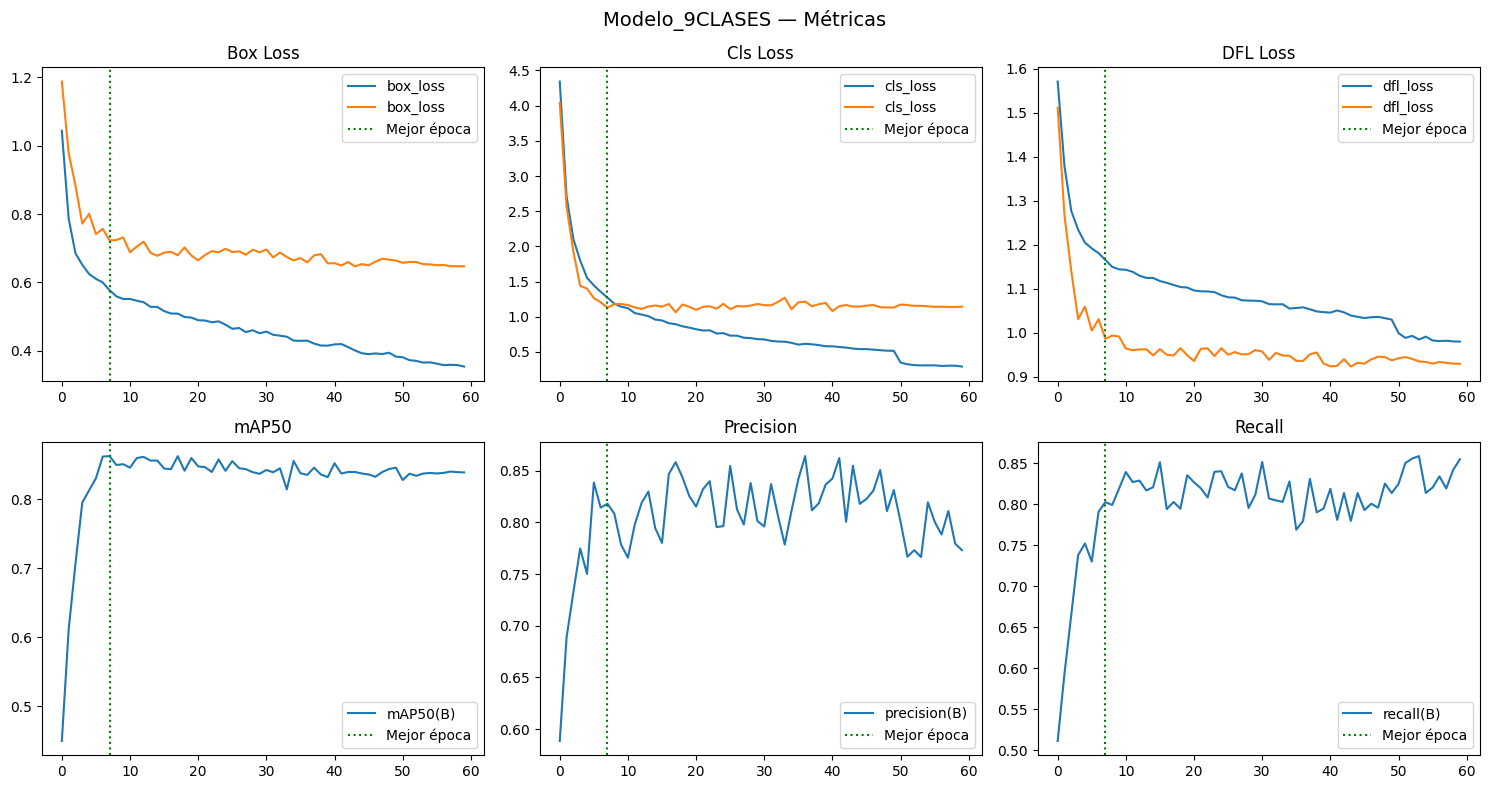

In [6]:
import pandas as pd
import matplotlib.pyplot as plt

df = pd.read_csv(f'{RESULTS_DIR}/results.csv')
df.columns = df.columns.str.strip()
mejor_epoca = df['metrics/mAP50(B)'].idxmax()

print(f'=== MEJOR ÉPOCA: {mejor_epoca+1}/{len(df)} ===')
for k in ['metrics/mAP50(B)','metrics/mAP50-95(B)','metrics/precision(B)','metrics/recall(B)',
          'train/box_loss','train/cls_loss','val/box_loss','val/cls_loss']:
    print(f'{k:22s}: {df[k].iloc[mejor_epoca]:.4f}')

fig, axes = plt.subplots(2, 3, figsize=(15, 8))
fig.suptitle(f'{RUN_NAME_DISEASE} — Métricas', fontsize=14)
for ax, (t, y) in zip(axes.flat, [
    ('Box Loss', ['train/box_loss','val/box_loss']),
    ('Cls Loss', ['train/cls_loss','val/cls_loss']),
    ('DFL Loss', ['train/dfl_loss','val/dfl_loss']),
    ('mAP50',   ['metrics/mAP50(B)']),
    ('Precision',['metrics/precision(B)']),
    ('Recall',  ['metrics/recall(B)'])]):
    for c in y:
        ax.plot(df[c], label=c.split('/')[-1])
    ax.axvline(x=mejor_epoca, color='g', linestyle=':', label='Mejor época')
    ax.set_title(t); ax.legend()
plt.tight_layout()
plt.savefig(f'{RESULTS_DIR}/metricas_{RUN_NAME_DISEASE}.png', dpi=150)
plt.show()


## 🧪 Validación en TEST con checkpoint de la mejor época

In [7]:
from ultralytics import YOLO
mejor_checkpoint = f'{RESULTS_DIR}/weights/epoch{mejor_epoca}.pt'
model_ckpt = YOLO(mejor_checkpoint)
metrics_ckpt = model_ckpt.val(data=f'{DATASET_LOCAL}/data.yaml',
                              split='test', imgsz=640, conf=CONF, plots=True)
print(f'mAP50: {metrics_ckpt.box.map50:.4f}  |  mAP50-95: {metrics_ckpt.box.map:.4f}')


Ultralytics 8.4.155 🚀 Python-3.13.15 torch-2.11.0+cu128 CUDA:0 (NVIDIA L4, 22563MiB)
Model summary (fused): 92 layers, 25,844,971 parameters, 0 gradients, 78.7 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 1513.7±543.9 MB/s, size: 54.5 KB)
val: Scanning /content/dataset_local/test/labels... 274 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 274/274 1.6Kit/s 0.2s
val: New cache created: /content/dataset_local/test/labels.cache
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 18/18 4.3it/s 4.2s
                   all        274        305      0.803       0.88      0.865      0.736
AmarillamientoAvanzado         27         27      0.768      0.852      0.862       0.81
 AmarillamientoInicial         20         20      0.738      0.845      0.804      0.775
     CogolleroAvanzado         50         55       0.85          1      0.976      0.565
      CogolleroInicial         64         81      0.741      0.741     

## 🧪 Validación con `best.pt` (por clase)

In [8]:
from ultralytics import YOLO
best_pt = f'{RESULTS_DIR}/weights/best.pt'
model_best = YOLO(best_pt)
m = model_best.val(data=f'{DATASET_LOCAL}/data.yaml', split='test',
                   imgsz=640, conf=CONF, plots=True)
print(f'mAP50: {m.box.map50:.4f}  |  mAP50-95: {m.box.map:.4f}\n')
names = m.names.values() if isinstance(m.names, dict) else m.names
for i, c in enumerate(names):
    print(f'  {c:28s} P={m.box.p[i]:.3f}  R={m.box.r[i]:.3f}  mAP50={m.box.ap50[i]:.3f}  mAP50-95={m.box.ap[i]:.3f}')


Ultralytics 8.4.155 🚀 Python-3.13.15 torch-2.11.0+cu128 CUDA:0 (NVIDIA L4, 22563MiB)
Model summary (fused): 92 layers, 25,844,971 parameters, 0 gradients, 78.7 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 1612.0±591.0 MB/s, size: 57.9 KB)
val: Scanning /content/dataset_local/test/labels.cache... 274 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 274/274 76.6Mit/s 0.0s
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 18/18 4.1it/s 4.3s
                   all        274        305      0.823      0.813      0.761      0.658
AmarillamientoAvanzado         27         27      0.662      0.852      0.691      0.659
 AmarillamientoInicial         20         20      0.684       0.65      0.558      0.558
     CogolleroAvanzado         50         55      0.968          1      0.995      0.618
      CogolleroInicial         64         81      0.811      0.794      0.746      0.377
PodredumbreRojaAvanzado         33      

# 🔥 Heatmaps GradCAM

In [9]:
import torch, numpy as np, cv2, os, glob
import matplotlib.pyplot as plt
from ultralytics import YOLO
from pytorch_grad_cam import GradCAM
from pytorch_grad_cam.utils.image import show_cam_on_image

class YOLOClassScore(torch.nn.Module):
    def __init__(self, yolo_nn, target_class):
        super().__init__()
        self.model = yolo_nn
        self.target_class = target_class
    def forward(self, x):
        outs = self.model(x)
        if not isinstance(outs, (list, tuple)): outs = [outs]
        score = 0.0
        for o in outs:
            if o.dim() == 4: score = score + o[:, 4+self.target_class].mean(dim=(1,2))
            else:            score = score + o[:, :, 4+self.target_class].mean(dim=1)
        return score.unsqueeze(1)

model = YOLO(f'{RESULTS_DIR}/weights/best.pt')
torch_model = model.model.cuda().eval()

def cargar_imagen(p, size=640):
    img = cv2.imread(p); img = cv2.resize(img, (size,size))
    return cv2.cvtColor(img, cv2.COLOR_BGR2RGB)

def elegir_imagenes_por_clase(split='test', n=2):
    img_dir = f'{DATASET_LOCAL}/{split}/images'
    lbl_dir = f'{DATASET_LOCAL}/{split}/labels'
    por_clase = {i: [] for i in range(NUM_CLASSES)}
    for lbl in sorted(glob.glob(f'{lbl_dir}/*.txt')):
        base = os.path.basename(lbl).replace('.txt','')
        cand = glob.glob(f'{img_dir}/{base}.*')
        if not cand: continue
        with open(lbl) as f:
            cids = {int(l.split()[0]) for l in f if l.strip()}
        for cid in cids:
            if len(por_clase[cid]) < n and cand[0] not in por_clase[cid]:
                por_clase[cid].append(cand[0])
        if all(len(v) >= n for v in por_clase.values()): break
    return por_clase

def generar_heatmap(img_path, save_path=None):
    img_rgb = cargar_imagen(img_path)
    tensor = torch.from_numpy(np.float32(img_rgb)/255.).permute(2,0,1).unsqueeze(0).cuda()
    res = model.predict(img_path, conf=CONF, imgsz=640, verbose=False)[0]
    if len(res.boxes) == 0: print('  sin detección'); return
    idx = int(res.boxes.conf.argmax())
    cid = int(res.boxes.cls[idx]); cname = model.names[cid]
    conf_t = float(res.boxes.conf[idx])
    wrapper = YOLOClassScore(torch_model, cid).eval()
    try:
        cam = GradCAM(model=wrapper, target_layers=[torch_model.model[8]])
        gray = cam(input_tensor=tensor)[0]
    except Exception as e:
        print(f'  fallback CAM: {e}')
        acts = {}
        h = torch_model.model[8].register_forward_hook(
            lambda m,i,o: acts.update({'a': o.detach()}) if isinstance(o, torch.Tensor) else None)
        with torch.no_grad(): torch_model(tensor)
        h.remove()
        f = acts['a'].squeeze(0).mean(0).cpu().numpy()
        f = np.maximum(f,0); f = (f-f.min())/(f.max()-f.min()+1e-8)
        gray = cv2.resize(f,(640,640))
    overlay = show_cam_on_image(np.float32(img_rgb)/255., gray, use_rgb=True)
    fig, ax = plt.subplots(1,3,figsize=(15,5))
    fig.suptitle(f'{cname} (conf={conf_t:.2%})', fontsize=13)
    ax[0].imshow(img_rgb);  ax[0].set_title('Original');  ax[0].axis('off')
    ax[1].imshow(overlay);  ax[1].set_title(f'GradCAM -> {cname}'); ax[1].axis('off')
    ax[2].imshow(cv2.cvtColor(res.plot(), cv2.COLOR_BGR2RGB)); ax[2].set_title('Detecciones'); ax[2].axis('off')
    plt.tight_layout()
    if save_path:
        plt.savefig(save_path, dpi=150, bbox_inches='tight'); print(f'  💾 {save_path}')
    plt.show()

HEATMAPS_DIR = f'{RESULTS_DIR}/heatmaps'
os.makedirs(HEATMAPS_DIR, exist_ok=True)
IMGS_POR_CLASE = 2
sel = elegir_imagenes_por_clase('test', IMGS_POR_CLASE)
for cid, nombre in enumerate(CLASSES):
    for k, ruta in enumerate(sel.get(cid, [])):
        print(f'\n--- {nombre} ({k+1}) -> {os.path.basename(ruta)} ---')
        generar_heatmap(ruta, save_path=f'{HEATMAPS_DIR}/heatmap_{nombre}_{k+1}.png')


Output hidden; open in https://colab.research.google.com to view.

# 🧩 Matriz de confusión — Modelo de Enfermedades

Se calcula a partir del objeto `metrics.confusion_matrix` que devuelve Ultralytics al validar.
Se muestra la matriz **cruda** y **normalizada** (por fila) como heatmaps.


Ultralytics 8.4.155 🚀 Python-3.13.15 torch-2.11.0+cu128 CUDA:0 (NVIDIA L4, 22563MiB)
Model summary (fused): 92 layers, 25,844,971 parameters, 0 gradients, 78.7 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 1691.2±546.7 MB/s, size: 48.2 KB)
val: Scanning /content/dataset_local/test/labels.cache... 274 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 274/274 95.8Mit/s 0.0s
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 18/18 5.3it/s 3.4s
                   all        274        305      0.823      0.813      0.761      0.658
Speed: 0.7ms preprocess, 9.3ms inference, 0.0ms loss, 0.7ms postprocess per image


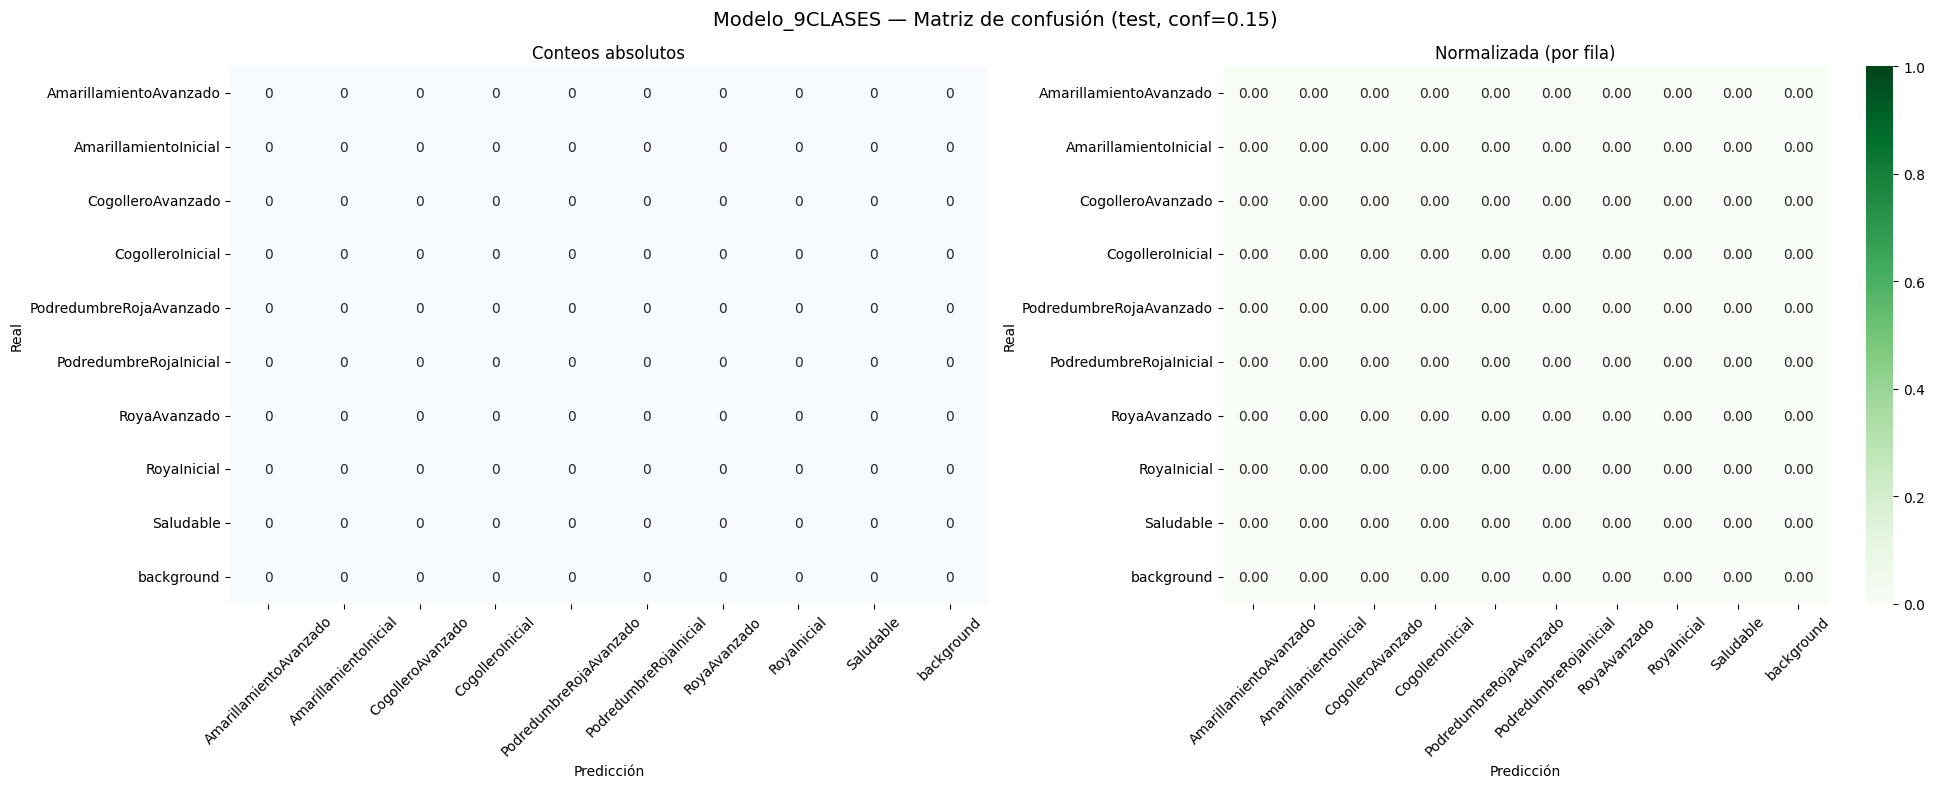


=== Top errores (real → predicho) ===

💾 Guardado: /content/drive/MyDrive/10mo Ciclo/TALLER/PRUEBA 1/Modelo_9CLASES/matriz_confusion_Modelo_9CLASES.png


In [10]:
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from ultralytics import YOLO

# Validación para obtener la matriz de confusión
model_cm = YOLO(f'{RESULTS_DIR}/weights/best.pt')
m_cm = model_cm.val(
    data=f'{DATASET_LOCAL}/data.yaml',
    split='test',
    imgsz=640,
    conf=CONF,
    plots=False,   # no regenerar plots auto
    verbose=False,
)

# Extraer matriz (shape: nc+1 x nc+1, última fila/col = background)
cm = np.array(m_cm.confusion_matrix.matrix, dtype=float)
n = cm.shape[0]
labels = list(m_cm.names.values()) if isinstance(m_cm.names, dict) else list(m_cm.names)
if len(labels) == n - 1:
    labels = labels + ['background']

cm_norm = cm / np.maximum(cm.sum(axis=1, keepdims=True), 1e-9)

fig, axes = plt.subplots(1, 2, figsize=(20, 8))
fig.suptitle(f'{RUN_NAME_DISEASE} — Matriz de confusión (test, conf={CONF})', fontsize=14)

sns.heatmap(cm, annot=True, fmt='.0f', cmap='Blues',
            xticklabels=labels, yticklabels=labels, ax=axes[0], cbar=False)
axes[0].set_title('Conteos absolutos')
axes[0].set_xlabel('Predicción'); axes[0].set_ylabel('Real')
axes[0].tick_params(axis='x', rotation=45); axes[0].tick_params(axis='y', rotation=0)

sns.heatmap(cm_norm, annot=True, fmt='.2f', cmap='Greens',
            xticklabels=labels, yticklabels=labels, ax=axes[1], vmin=0, vmax=1)
axes[1].set_title('Normalizada (por fila)')
axes[1].set_xlabel('Predicción'); axes[1].set_ylabel('Real')
axes[1].tick_params(axis='x', rotation=45); axes[1].tick_params(axis='y', rotation=0)

plt.tight_layout()
out_path = f'{RESULTS_DIR}/matriz_confusion_{RUN_NAME_DISEASE}.png'
plt.savefig(out_path, dpi=150, bbox_inches='tight')
plt.show()

# Reporte de errores más frecuentes
print('\n=== Top errores (real → predicho) ===')
errs = []
for i, real in enumerate(labels):
    for j, pred in enumerate(labels):
        if i != j and cm[i, j] > 0:
            errs.append((cm[i, j], real, pred))
errs.sort(reverse=True)
for cnt, real, pred in errs[:10]:
    print(f'  {int(cnt):4d}  {real:28s} → {pred}')
print(f'\n💾 Guardado: {out_path}')


# 🍃 Modelo Detector de Hoja (YOLOv8n)

In [11]:
from ultralytics import YOLO
model_leaf = YOLO('yolov8n.pt')
results_leaf = model_leaf.train(
    data=f'{LEAF_DATASET_LOCAL}/data.yaml',
    epochs=60, imgsz=640, batch=8, patience=0, save_period=1,
    device='cuda', pretrained=True, optimizer='SGD',
    lr0=0.001, lrf=0.01, cos_lr=True,
    box=8.0, cls=0.75, momentum=0.937, weight_decay=0.0005,
    workers=2,
    hsv_h=0.02, hsv_s=0.8, hsv_v=0.5,
    scale=0.3, translate=0.15, copy_paste=0.1,
    project=BASE_DRIVE, name=RUN_NAME_LEAF, exist_ok=True
)
print(f'Entrenamiento hoja completado. Resultados: {results_leaf.save_dir}')


Ultralytics 8.4.155 🚀 Python-3.13.15 torch-2.11.0+cu128 CUDA:0 (NVIDIA L4, 22563MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=8, bgr=0.0, box=8.0, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.75, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.1, copy_paste_mode=flip, cos_lr=True, cutmix=0.0, data=/content/leaf_dataset_local/data.yaml, degrees=0.0, deterministic=True, device=0, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=60, erasing=0.4, exist_ok=True, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.02, hsv_s=0.8, hsv_v=0.5, imgsz=640, iou=0.7, keras=False, kobj=1.0, line_width=None, lr0=0.001, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yolov8n.pt, momentum=0.937, mosaic=1.0, multi_scale=0.0, name=Modelo_HOJA, nbs=64, nms=None, opset=No

## 🧪 Validación del detector de hoja en TEST

In [12]:
from ultralytics import YOLO
model_leaf_best = YOLO(f'{LEAF_RESULTS_DIR}/weights/best.pt')
m_leaf = model_leaf_best.val(
    data=f'{LEAF_DATASET_LOCAL}/data.yaml',
    split='test', imgsz=640, conf=CONF, plots=True
)
print(f'mAP50    : {m_leaf.box.map50:.4f}')
print(f'mAP50-95 : {m_leaf.box.map:.4f}')
print(f'Precision: {m_leaf.box.mp:.4f}')
print(f'Recall   : {m_leaf.box.mr:.4f}')


Ultralytics 8.4.155 🚀 Python-3.13.15 torch-2.11.0+cu128 CUDA:0 (NVIDIA L4, 22563MiB)
Model summary (fused): 72 layers, 3,005,843 parameters, 0 gradients, 8.1 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 921.9±291.6 MB/s, size: 35.7 KB)
val: Scanning /content/leaf_dataset_local/test/labels... 253 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 253/253 1.5Kit/s 0.2s
val: /content/leaf_dataset_local/test/images/redrot-405-_jpeg_jpg.rf.8579c8bd9ac522784204d21573687c90.jpg: 1 duplicate labels removed
val: New cache created: /content/leaf_dataset_local/test/labels.cache
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 16/16 6.7it/s 2.4s
                   all        253        284      0.917      0.895      0.909      0.703
Speed: 1.4ms preprocess, 2.2ms inference, 0.0ms loss, 1.2ms postprocess per image
Results saved to /content/runs/detect/val-4
mAP50    : 0.9090
mAP50-95 : 0.7034
Precision: 0.9170
Recall   : 0.8946

# 🧩 Matriz de confusión — Detector de Hoja

Aunque el detector de hoja es de 1 clase, la matriz incluye la fila/columna **background** y permite ver falsos positivos / falsos negativos del filtro.


Ultralytics 8.4.155 🚀 Python-3.13.15 torch-2.11.0+cu128 CUDA:0 (NVIDIA L4, 22563MiB)
Model summary (fused): 72 layers, 3,005,843 parameters, 0 gradients, 8.1 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 1340.4±516.7 MB/s, size: 47.3 KB)
val: Scanning /content/leaf_dataset_local/test/labels.cache... 253 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 253/253 66.3Mit/s 0.0s
val: /content/leaf_dataset_local/test/images/redrot-405-_jpeg_jpg.rf.8579c8bd9ac522784204d21573687c90.jpg: 1 duplicate labels removed
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 16/16 13.3it/s 1.2s
                   all        253        284      0.917      0.895      0.909      0.703
Speed: 0.7ms preprocess, 1.5ms inference, 0.0ms loss, 0.6ms postprocess per image


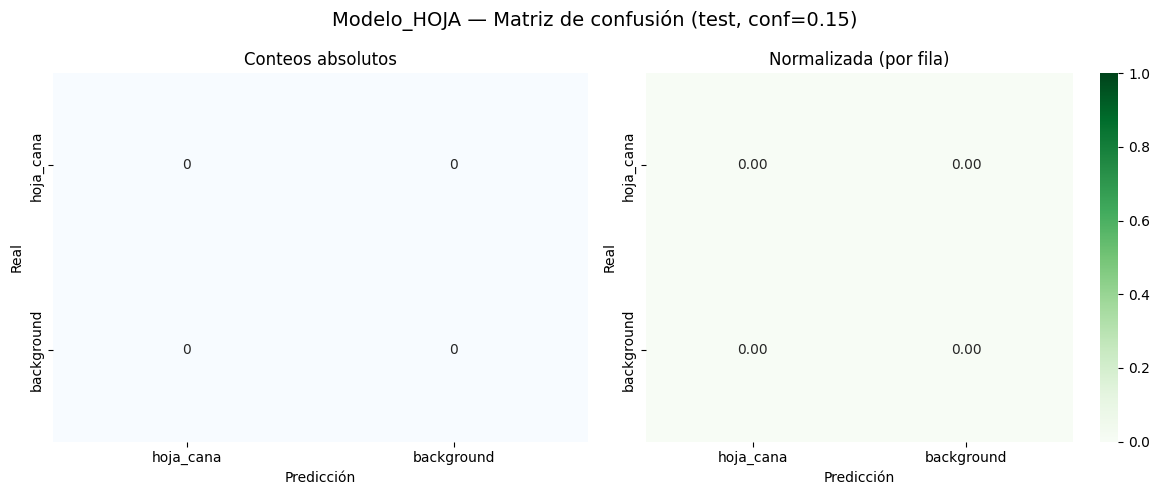

💾 Guardado: /content/drive/MyDrive/10mo Ciclo/TALLER/PRUEBA 1/Modelo_HOJA/matriz_confusion_Modelo_HOJA.png


In [13]:
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from ultralytics import YOLO

model_leaf_cm = YOLO(f'{LEAF_RESULTS_DIR}/weights/best.pt')
m_l = model_leaf_cm.val(
    data=f'{LEAF_DATASET_LOCAL}/data.yaml',
    split='test', imgsz=640, conf=CONF, plots=False, verbose=False,
)

cm_l = np.array(m_l.confusion_matrix.matrix, dtype=float)
labels_l = list(m_l.names.values()) if isinstance(m_l.names, dict) else list(m_l.names)
if len(labels_l) == cm_l.shape[0] - 1:
    labels_l = labels_l + ['background']
cm_l_norm = cm_l / np.maximum(cm_l.sum(axis=1, keepdims=True), 1e-9)

fig, axes = plt.subplots(1, 2, figsize=(12, 5))
fig.suptitle(f'{RUN_NAME_LEAF} — Matriz de confusión (test, conf={CONF})', fontsize=14)

sns.heatmap(cm_l, annot=True, fmt='.0f', cmap='Blues',
            xticklabels=labels_l, yticklabels=labels_l, ax=axes[0], cbar=False)
axes[0].set_title('Conteos absolutos')
axes[0].set_xlabel('Predicción'); axes[0].set_ylabel('Real')

sns.heatmap(cm_l_norm, annot=True, fmt='.2f', cmap='Greens',
            xticklabels=labels_l, yticklabels=labels_l, ax=axes[1], vmin=0, vmax=1)
axes[1].set_title('Normalizada (por fila)')
axes[1].set_xlabel('Predicción'); axes[1].set_ylabel('Real')

plt.tight_layout()
out_leaf_cm = f'{LEAF_RESULTS_DIR}/matriz_confusion_{RUN_NAME_LEAF}.png'
plt.savefig(out_leaf_cm, dpi=150, bbox_inches='tight')
plt.show()
print(f'💾 Guardado: {out_leaf_cm}')


# 🔗 Pipeline completo CañaScan (2 modelos)

1. Detector hoja (conf=0.15) → si hay hoja → 2. Enfermedades (conf=0.15). Si no → rechazado.


In [14]:
from ultralytics import YOLO
import os, glob, cv2, numpy as np, pandas as pd, matplotlib.pyplot as plt

print('Cargando modelos...')
model_leaf_pipe = YOLO(f'{LEAF_RESULTS_DIR}/weights/best.pt')
model_dis_pipe  = YOLO(f'{RESULTS_DIR}/weights/best.pt')
os.makedirs(PRUEBA_REAL_RESULTADOS, exist_ok=True)

def pipeline_canascan(img_path, verbose=False):
    r = {'img_path': img_path, 'es_hoja': False, 'conf_hoja': 0.0,
         'bbox_hoja': None, 'enfermedad': None, 'conf_enfermedad': 0.0,
         'todas_detecciones': []}
    res_leaf = model_leaf_pipe.predict(img_path, conf=CONF, imgsz=640, verbose=False)[0]
    if len(res_leaf.boxes) == 0:
        if verbose: print(f'  ❌ no hoja: {os.path.basename(img_path)}')
        return r, res_leaf, None
    idx = int(res_leaf.boxes.conf.argmax())
    r['es_hoja']   = True
    r['conf_hoja'] = float(res_leaf.boxes.conf[idx])
    r['bbox_hoja'] = res_leaf.boxes.xyxy[idx].tolist()
    if verbose: print(f'  ✅ hoja ({r["conf_hoja"]:.2%})')
    res_dis = model_dis_pipe.predict(img_path, conf=CONF, imgsz=640, verbose=False)[0]
    if len(res_dis.boxes) > 0:
        idx2 = int(res_dis.boxes.conf.argmax())
        r['enfermedad']      = model_dis_pipe.names[int(res_dis.boxes.cls[idx2])]
        r['conf_enfermedad'] = float(res_dis.boxes.conf[idx2])
        r['todas_detecciones'] = [{'clase': model_dis_pipe.names[int(b.cls)],
                                   'conf': float(b.conf),
                                   'bbox': b.xyxy[0].tolist()} for b in res_dis.boxes]
        if verbose: print(f'     🦠 {r["enfermedad"]} ({r["conf_enfermedad"]:.2%})')
    return r, res_leaf, res_dis

def pipeline_batch(paths):
    filas = []
    for p in paths:
        r, _, _ = pipeline_canascan(p)
        filas.append({'imagen': os.path.basename(p), 'es_hoja': r['es_hoja'],
                      'conf_hoja': round(r['conf_hoja'],3),
                      'enfermedad': r['enfermedad'],
                      'conf_enfermedad': round(r['conf_enfermedad'],3),
                      'n_detecciones': len(r['todas_detecciones'])})
    return pd.DataFrame(filas)

def visualizar_pipeline(img_path, save_path=None):
    r, res_leaf, res_dis = pipeline_canascan(img_path, verbose=True)
    img_rgb = cv2.cvtColor(cv2.imread(img_path), cv2.COLOR_BGR2RGB)
    fig, ax = plt.subplots(1, 3, figsize=(15, 5))
    t = os.path.basename(img_path)
    t += f' → {r["enfermedad"] or "sin enfermedad"}' if r['es_hoja'] else ' → RECHAZADO'
    fig.suptitle(t, fontsize=13)
    ax[0].imshow(img_rgb); ax[0].set_title('Original'); ax[0].axis('off')
    ax[1].imshow(cv2.cvtColor(res_leaf.plot(), cv2.COLOR_BGR2RGB)) if res_leaf is not None else ax[1].imshow(img_rgb)
    ax[1].set_title(f'1) Hoja (conf={r["conf_hoja"]:.2%})'); ax[1].axis('off')
    if res_dis is not None:
        ax[2].imshow(cv2.cvtColor(res_dis.plot(), cv2.COLOR_BGR2RGB))
        ax[2].set_title(f'2) {r["enfermedad"]} ({r["conf_enfermedad"]:.2%})')
    else:
        ax[2].imshow(np.zeros_like(img_rgb))
        ax[2].text(320,320,'No ejecutado', ha='center', va='center', color='red', fontsize=14)
        ax[2].set_title('2) Enfermedad (SKIP)')
    ax[2].axis('off')
    plt.tight_layout()
    if save_path:
        plt.savefig(save_path, dpi=150, bbox_inches='tight'); print(f'  💾 {save_path}')
    plt.show()
    return r


Cargando modelos...


## ✅ Prueba 1 — Hojas (`prueba_real/hojas`)

In [15]:
EXT = ('*.jpg','*.jpeg','*.png','*.bmp','*.webp')
def listar_imgs(carpeta):
    out = []
    for e in EXT:
        out += glob.glob(f'{carpeta}/{e}') + glob.glob(f'{carpeta}/{e.upper()}')
    return sorted(set(out))

paths_hojas = listar_imgs(PRUEBA_REAL_HOJAS)
print(f'Imágenes de hojas: {len(paths_hojas)}')

if paths_hojas:
    OUT_HOJAS = f'{PRUEBA_REAL_RESULTADOS}/hojas'
    os.makedirs(OUT_HOJAS, exist_ok=True)
    for i, p in enumerate(paths_hojas):
        print(f'\n[{i+1}/{len(paths_hojas)}] {os.path.basename(p)}')
        visualizar_pipeline(p, save_path=f'{OUT_HOJAS}/pipeline_{i+1:03d}.png')
    df_hojas = pipeline_batch(paths_hojas)
    print(df_hojas.to_string(index=False))
    print(f'\nHojas aceptadas: {df_hojas["es_hoja"].sum()}/{len(df_hojas)}')
    df_hojas.to_csv(f'{PRUEBA_REAL_RESULTADOS}/resumen_hojas.csv', index=False)


Output hidden; open in https://colab.research.google.com to view.

## ❌ Prueba 2 — Negativos (`prueba_real/negativos`)

In [16]:
paths_neg = listar_imgs(PRUEBA_REAL_NEG)
print(f'Imágenes negativas: {len(paths_neg)}')

if paths_neg:
    OUT_NEG = f'{PRUEBA_REAL_RESULTADOS}/negativos'
    os.makedirs(OUT_NEG, exist_ok=True)
    for i, p in enumerate(paths_neg):
        print(f'\n[{i+1}/{len(paths_neg)}] {os.path.basename(p)}')
        visualizar_pipeline(p, save_path=f'{OUT_NEG}/pipeline_{i+1:03d}.png')
    df_neg = pipeline_batch(paths_neg)
    print(df_neg.to_string(index=False))
    print(f'\nRechazadas OK: {(~df_neg["es_hoja"]).sum()}/{len(df_neg)}')
    print(f'Falsos positivos: {df_neg["es_hoja"].sum()}/{len(df_neg)}')
    df_neg.to_csv(f'{PRUEBA_REAL_RESULTADOS}/resumen_negativos.csv', index=False)


Output hidden; open in https://colab.research.google.com to view.

# 📊 Gráficas del pipeline completo

Visualizaciones agregadas de la corrida sobre `prueba_real/`:
- Distribución de clases detectadas en hojas
- Histograma de confianzas (hoja y enfermedad)
- Pastel: aceptadas vs rechazadas en cada set


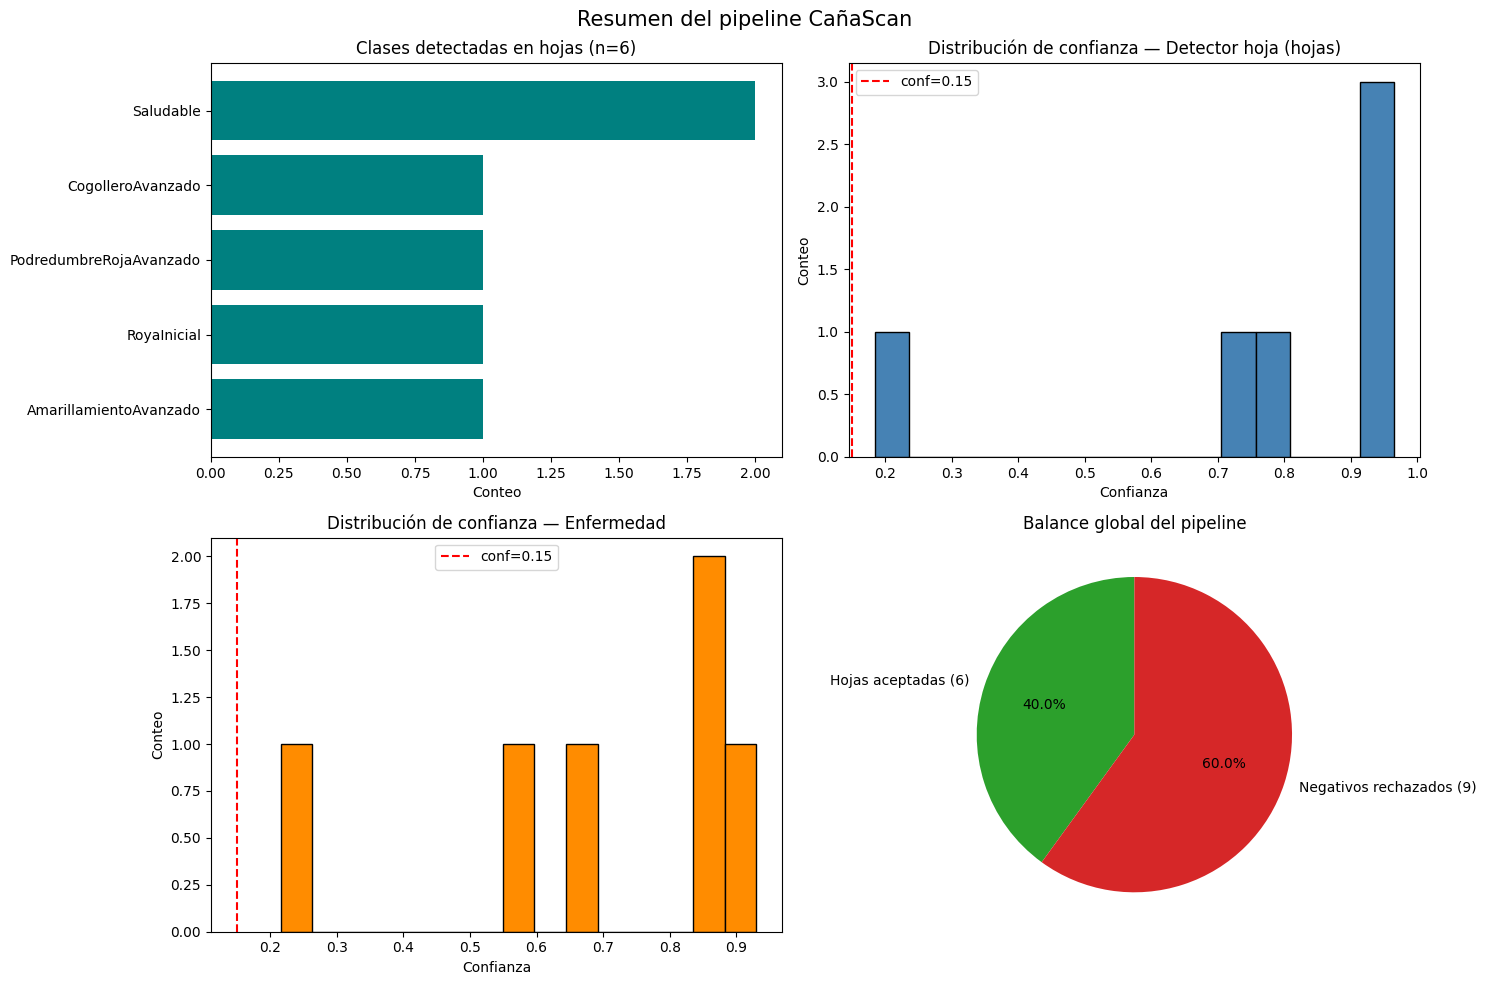

💾 Guardado: /content/drive/MyDrive/10mo Ciclo/TALLER/PRUEBA 1/prueba_real/resultados/graficas_pipeline.png


In [17]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

try: _ = df_hojas
except NameError: df_hojas = pd.DataFrame()
try: _ = df_neg
except NameError: df_neg = pd.DataFrame()

if df_hojas.empty and df_neg.empty:
    print('⚠️  No hay datos. Corre antes las pruebas del pipeline.')
else:
    fig, axes = plt.subplots(2, 2, figsize=(15, 10))
    fig.suptitle('Resumen del pipeline CañaScan', fontsize=15)

    # (1) Distribución de clases detectadas en hojas
    ax = axes[0, 0]
    if not df_hojas.empty:
        conteo = df_hojas['enfermedad'].fillna('sin_deteccion').value_counts()
        ax.barh(conteo.index, conteo.values, color='teal')
        ax.set_title(f'Clases detectadas en hojas (n={len(df_hojas)})')
        ax.set_xlabel('Conteo')
    else:
        ax.text(0.5, 0.5, 'Sin datos', ha='center', va='center')
    ax.invert_yaxis()

    # (2) Histograma de confianza de hoja
    ax = axes[0, 1]
    if not df_hojas.empty:
        ch = df_hojas[df_hojas['es_hoja']]['conf_hoja']
        if len(ch) > 0:
            ax.hist(ch, bins=15, color='steelblue', edgecolor='black')
            ax.axvline(CONF, color='r', linestyle='--', label=f'conf={CONF}')
            ax.set_title('Distribución de confianza — Detector hoja (hojas)')
            ax.set_xlabel('Confianza'); ax.set_ylabel('Conteo'); ax.legend()
        else:
            ax.text(0.5, 0.5, 'Sin hojas aceptadas', ha='center', va='center')
    else:
        ax.text(0.5, 0.5, 'Sin datos', ha='center', va='center')

    # (3) Histograma de confianza de enfermedad
    ax = axes[1, 0]
    if not df_hojas.empty:
        ce = df_hojas['conf_enfermedad'].replace(0, np.nan).dropna()
        if len(ce) > 0:
            ax.hist(ce, bins=15, color='darkorange', edgecolor='black')
            ax.axvline(CONF, color='r', linestyle='--', label=f'conf={CONF}')
            ax.set_title('Distribución de confianza — Enfermedad')
            ax.set_xlabel('Confianza'); ax.set_ylabel('Conteo'); ax.legend()
        else:
            ax.text(0.5, 0.5, 'Sin enfermedades detectadas', ha='center', va='center')
    else:
        ax.text(0.5, 0.5, 'Sin datos', ha='center', va='center')

    # (4) Pastel: hojas aceptadas vs rechazadas + negativos
    ax = axes[1, 1]
    h_ok  = int(df_hojas['es_hoja'].sum()) if not df_hojas.empty else 0
    h_bad = len(df_hojas) - h_ok
    n_ok  = int((~df_neg['es_hoja']).sum()) if not df_neg.empty else 0
    n_bad = int(df_neg['es_hoja'].sum()) if not df_neg.empty else 0

    vals = [h_ok, h_bad, n_ok, n_bad]
    lbls = [f'Hojas aceptadas ({h_ok})', f'Hojas rechazadas ({h_bad})',
            f'Negativos rechazados ({n_ok})', f'Negativos aceptados ({n_bad})']
    cols = ['#2ca02c', '#d62728', '#1f77b4', '#ff7f0e']
    vals_plot = [v for v in vals if v > 0]
    lbls_plot = [l for l, v in zip(lbls, vals) if v > 0]
    if vals_plot:
        ax.pie(vals_plot, labels=lbls_plot, colors=cols[:len(vals_plot)],
               autopct='%1.1f%%', startangle=90)
        ax.set_title('Balance global del pipeline')
    else:
        ax.text(0.5, 0.5, 'Sin datos', ha='center', va='center')

    plt.tight_layout()
    out = f'{PRUEBA_REAL_RESULTADOS}/graficas_pipeline.png'
    plt.savefig(out, dpi=150, bbox_inches='tight')
    plt.show()
    print(f'💾 Guardado: {out}')


# 🧩 Matriz de confusión — Pipeline completo (binaria)

Ground truth:
- `prueba_real/hojas` → **hoja** (positivo real)
- `prueba_real/negativos` → **no-hoja** (negativo real)

Predicción (del detector de hoja dentro del pipeline):
- `es_hoja=True` → **hoja**
- `es_hoja=False` → **no-hoja**


# 🖼️ Grid visual — resultados del pipeline

Vista compacta de todos los resultados del pipeline (thumbnails con predicción).


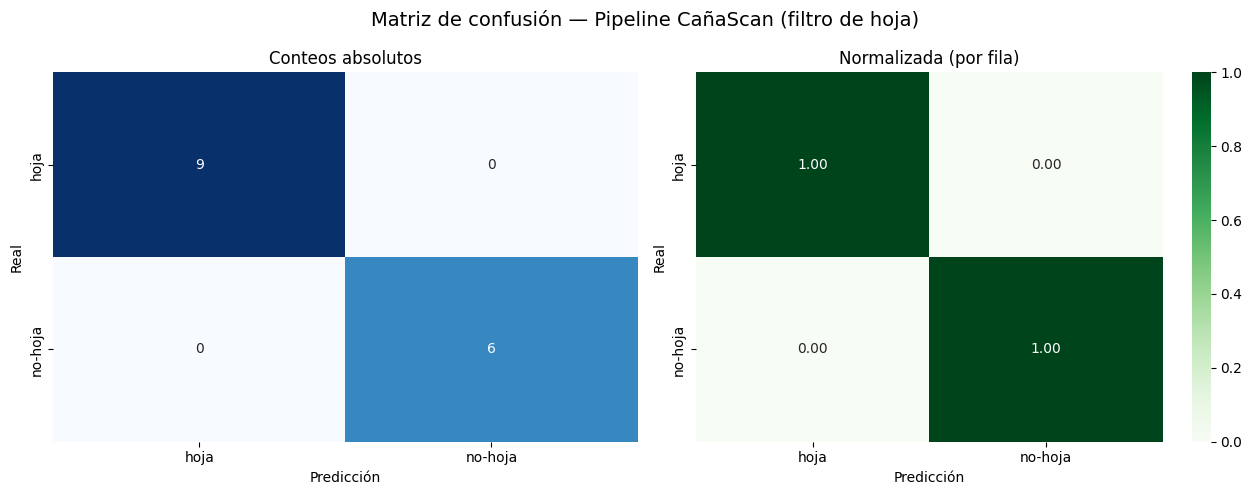


=== MÉTRICAS DEL FILTRO (nivel pipeline) ===
  Total imágenes   : 15
  TP=9  FN=0  FP=0  TN=6
  Accuracy         : 1.0000
  Precision (hoja) : 1.0000
  Recall (hoja)    : 1.0000
  Especificidad    : 1.0000
  FPR              : 0.0000
  FNR              : 0.0000

💾 Guardado: /content/drive/MyDrive/10mo Ciclo/TALLER/PRUEBA 1/prueba_real/resultados/matriz_confusion_pipeline.png


In [18]:
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

try:
    _ = df_hojas; _ = df_neg
    ok_data = True
except NameError:
    ok_data = False

if not ok_data or (df_hojas.empty and df_neg.empty):
    print('⚠️  Corre antes las pruebas del pipeline.')
else:
    # Ground truth (1=hoja, 0=no-hoja) y predicción
    y_true = [1]*len(df_hojas) + [0]*len(df_neg)
    y_pred = [1 if v else 0 for v in df_hojas['es_hoja']] + \
             [1 if v else 0 for v in df_neg['es_hoja']]

    # Matriz 2x2: filas=real, cols=predicho (orden: [hoja, no-hoja])
    cm = np.zeros((2, 2), dtype=int)
    for t, p in zip(y_true, y_pred):
        cm[t, p] += 1

    labels = ['hoja', 'no-hoja']
    fig, axes = plt.subplots(1, 2, figsize=(13, 5))
    fig.suptitle('Matriz de confusión — Pipeline CañaScan (filtro de hoja)', fontsize=14)

    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
                xticklabels=labels, yticklabels=labels, ax=axes[0], cbar=False)
    axes[0].set_xlabel('Predicción'); axes[0].set_ylabel('Real')
    axes[0].set_title('Conteos absolutos')

    cm_norm = cm / np.maximum(cm.sum(axis=1, keepdims=True), 1e-9)
    sns.heatmap(cm_norm, annot=True, fmt='.2f', cmap='Greens',
                xticklabels=labels, yticklabels=labels, ax=axes[1], vmin=0, vmax=1)
    axes[1].set_xlabel('Predicción'); axes[1].set_ylabel('Real')
    axes[1].set_title('Normalizada (por fila)')

    plt.tight_layout()
    out = f'{PRUEBA_REAL_RESULTADOS}/matriz_confusion_pipeline.png'
    plt.savefig(out, dpi=150, bbox_inches='tight')
    plt.show()

    # Métricas derivadas (filtro binario)
    TP = cm[0, 0]; FN = cm[0, 1]; FP = cm[1, 0]; TN = cm[1, 1]
    total = TP + FN + FP + TN

    TPR = TP / max(TP + FN, 1)          # sensibilidad / recall
    TNR = TN / max(TN + FP, 1)          # especificidad
    FPR = FP / max(FP + TN, 1)          # falsos positivos
    FNR = FN / max(FN + TP, 1)          # falsos negativos
    acc = (TP + TN) / max(total, 1)
    prec = TP / max(TP + FP, 1)

    print('\n=== MÉTRICAS DEL FILTRO (nivel pipeline) ===')
    print(f'  Total imágenes   : {total}')
    print(f'  TP={TP}  FN={FN}  FP={FP}  TN={TN}')
    print(f'  Accuracy         : {acc:.4f}')
    print(f'  Precision (hoja) : {prec:.4f}')
    print(f'  Recall (hoja)    : {TPR:.4f}')
    print(f'  Especificidad    : {TNR:.4f}')
    print(f'  FPR              : {FPR:.4f}')
    print(f'  FNR              : {FNR:.4f}')
    print(f'\n💾 Guardado: {out}')


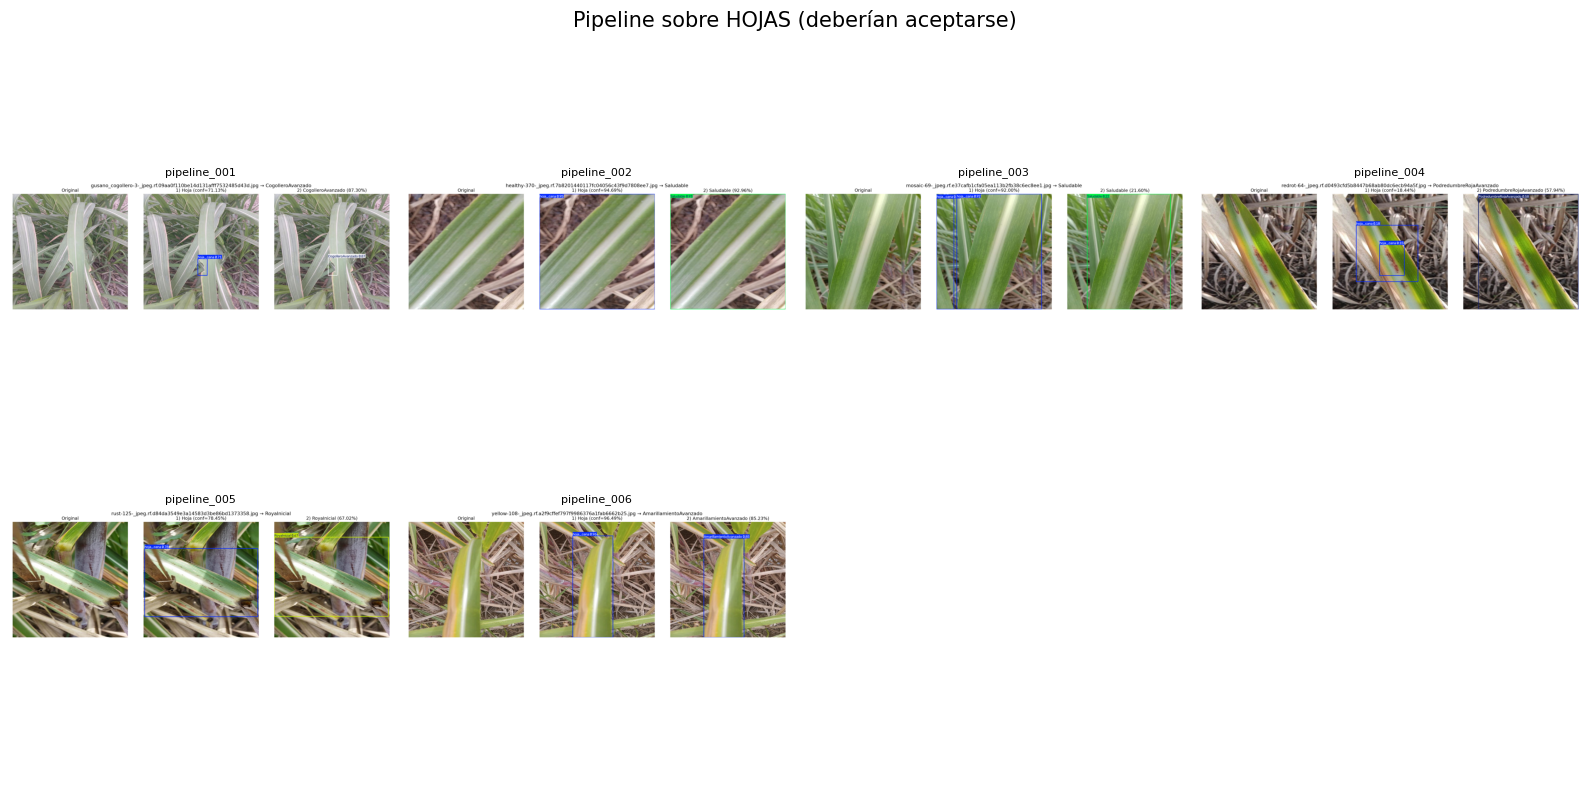

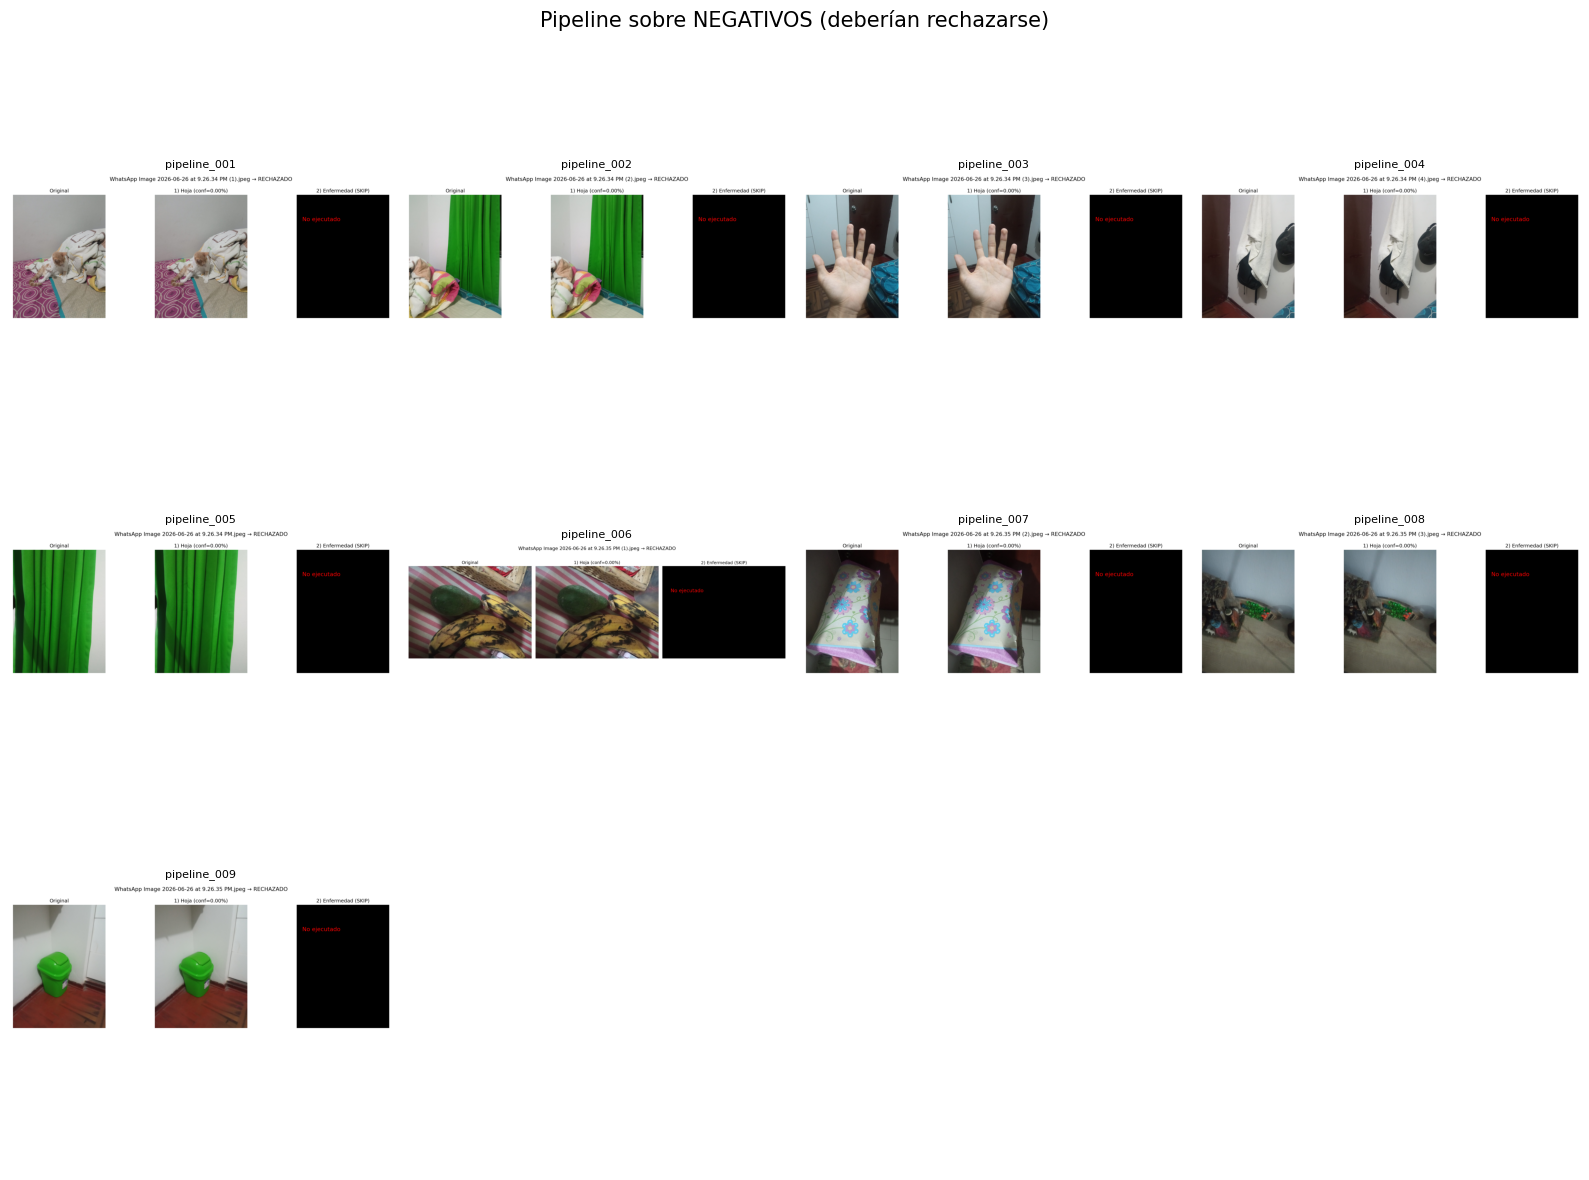

In [19]:
import cv2
import matplotlib.pyplot as plt
import glob as _glob
import os

def grid_resultados(carpeta, titulo, max_imgs=20):
    imgs = sorted(_glob.glob(f'{carpeta}/*.png'))
    if not imgs:
        print(f'⚠️  Sin resultados en {carpeta}')
        return
    imgs = imgs[:max_imgs]
    n = len(imgs)
    ncols = 4
    nrows = (n + ncols - 1) // ncols
    fig, axes = plt.subplots(nrows, ncols, figsize=(4*ncols, 4*nrows))
    fig.suptitle(titulo, fontsize=15)
    axes = axes.flatten() if nrows > 1 else [axes] if ncols == 1 else axes
    for i, ax in enumerate(axes):
        if i < n:
            img = cv2.imread(imgs[i])
            if img is not None:
                ax.imshow(cv2.cvtColor(img, cv2.COLOR_BGR2RGB))
            ax.set_title(os.path.basename(imgs[i]).replace('.png',''), fontsize=8)
        ax.axis('off')
    plt.tight_layout()
    plt.show()

# Hojas
grid_resultados(f'{PRUEBA_REAL_RESULTADOS}/hojas',
                'Pipeline sobre HOJAS (deberían aceptarse)')
# Negativos
grid_resultados(f'{PRUEBA_REAL_RESULTADOS}/negativos',
                'Pipeline sobre NEGATIVOS (deberían rechazarse)')


## 📊 Resumen global

In [20]:
print('=' * 60)
print('  RESUMEN GLOBAL DEL PIPELINE')
print('=' * 60)
try:
    print(f'\n📁 HOJAS: {len(df_hojas)}')
    print(f'   Aceptadas      : {int(df_hojas["es_hoja"].sum())} ({df_hojas["es_hoja"].mean():.1%})')
    print(f'   Con enfermedad : {int(df_hojas["enfermedad"].notna().sum())}')
except NameError: pass
try:
    print(f'\n📁 NEGATIVOS: {len(df_neg)}')
    print(f'   Rechazadas OK  : {int((~df_neg["es_hoja"]).sum())} ({(~df_neg["es_hoja"]).mean():.1%})')
    print(f'   Falsos posit.  : {int(df_neg["es_hoja"].sum())}')
except NameError: pass
print(f'\n📂 Resultados en: {PRUEBA_REAL_RESULTADOS}')


  RESUMEN GLOBAL DEL PIPELINE

📁 HOJAS: 6
   Aceptadas      : 6 (100.0%)
   Con enfermedad : 6

📁 NEGATIVOS: 9
   Rechazadas OK  : 9 (100.0%)
   Falsos posit.  : 0

📂 Resultados en: /content/drive/MyDrive/10mo Ciclo/TALLER/PRUEBA 1/prueba_real/resultados


Usando modelos ya cargados en el pipeline.
Conf hoja=0.2  |  conf enfermedad=0.15

=== MÉTRICAS DEL PIPELINE COMPLETO ===

Total imágenes test: 274
Rechazadas por Modelo Hoja: 2 (0.7%)

AmarillamientoAvanzado       P=67.65%  R=85.19%  F1=75.41%
AmarillamientoInicial        P=76.47%  R=65.00%  F1=70.27%
CogolleroAvanzado            P=85.94%  R=100.00%  F1=92.44%
CogolleroInicial             P=95.12%  R=96.30%  F1=95.71%
PodredumbreRojaAvanzado      P=67.50%  R=79.41%  F1=72.97%
PodredumbreRojaInicial       P=83.33%  R=52.63%  F1=64.52%
RoyaAvanzado                 P=83.33%  R=86.96%  F1=85.11%
RoyaInicial                  P=76.47%  R=81.25%  F1=78.79%
Saludable                    P=96.77%  R=100.00%  F1=98.36%

Precision media: 81.40%
Recall medio:    82.97%
F1 medio:        81.51%

=== mAP50 y mAP50-95 DEL PIPELINE ===

AmarillamientoAvanzado       mAP50=0.6699  mAP50-95=0.6209
AmarillamientoInicial        mAP50=0.5392  mAP50-95=0.5306
CogolleroAvanzado            mAP50=0.9968  mAP50-9

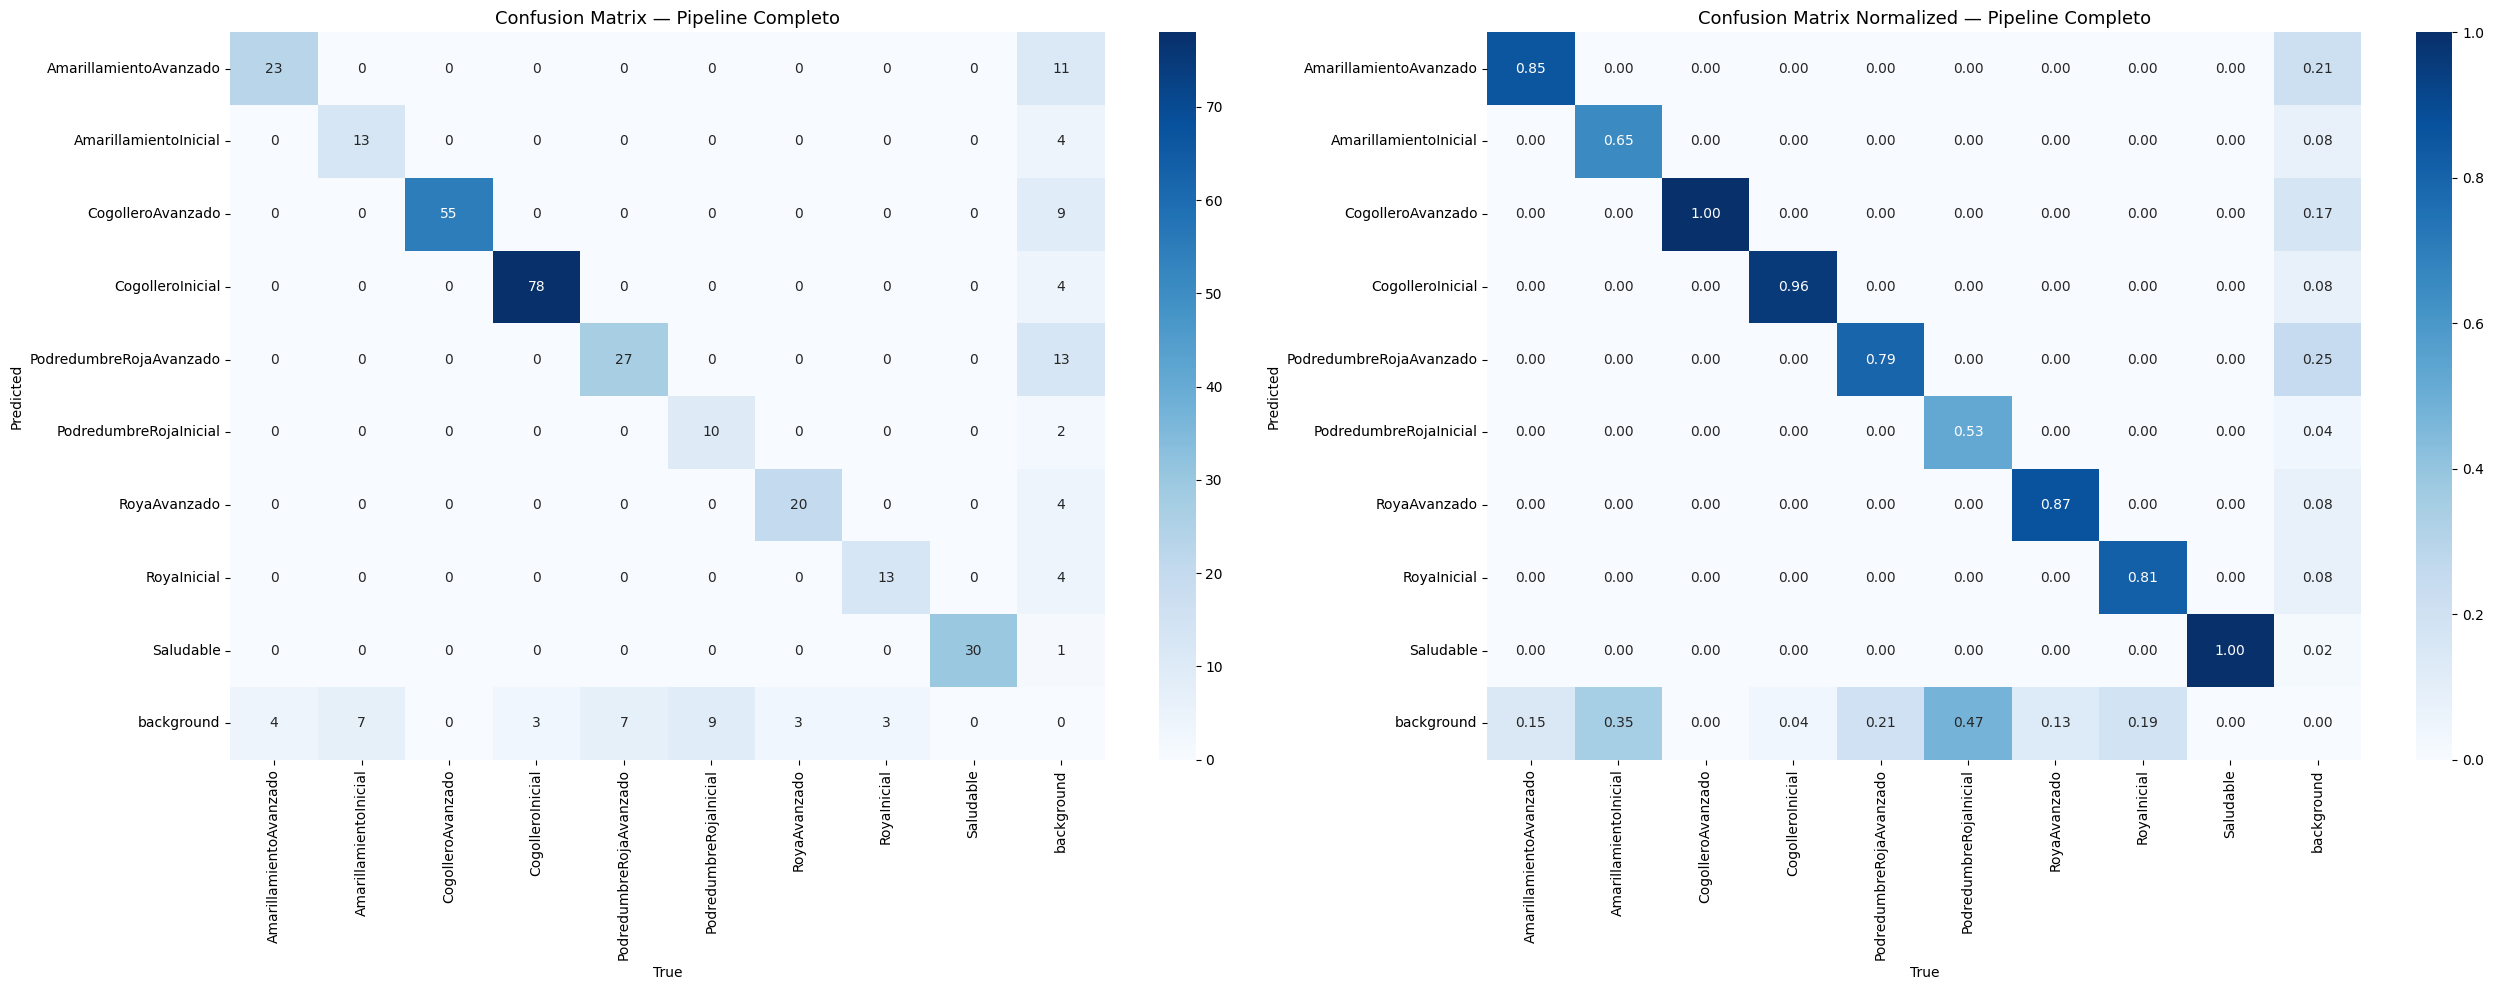

✅ Matriz de confusión guardada.


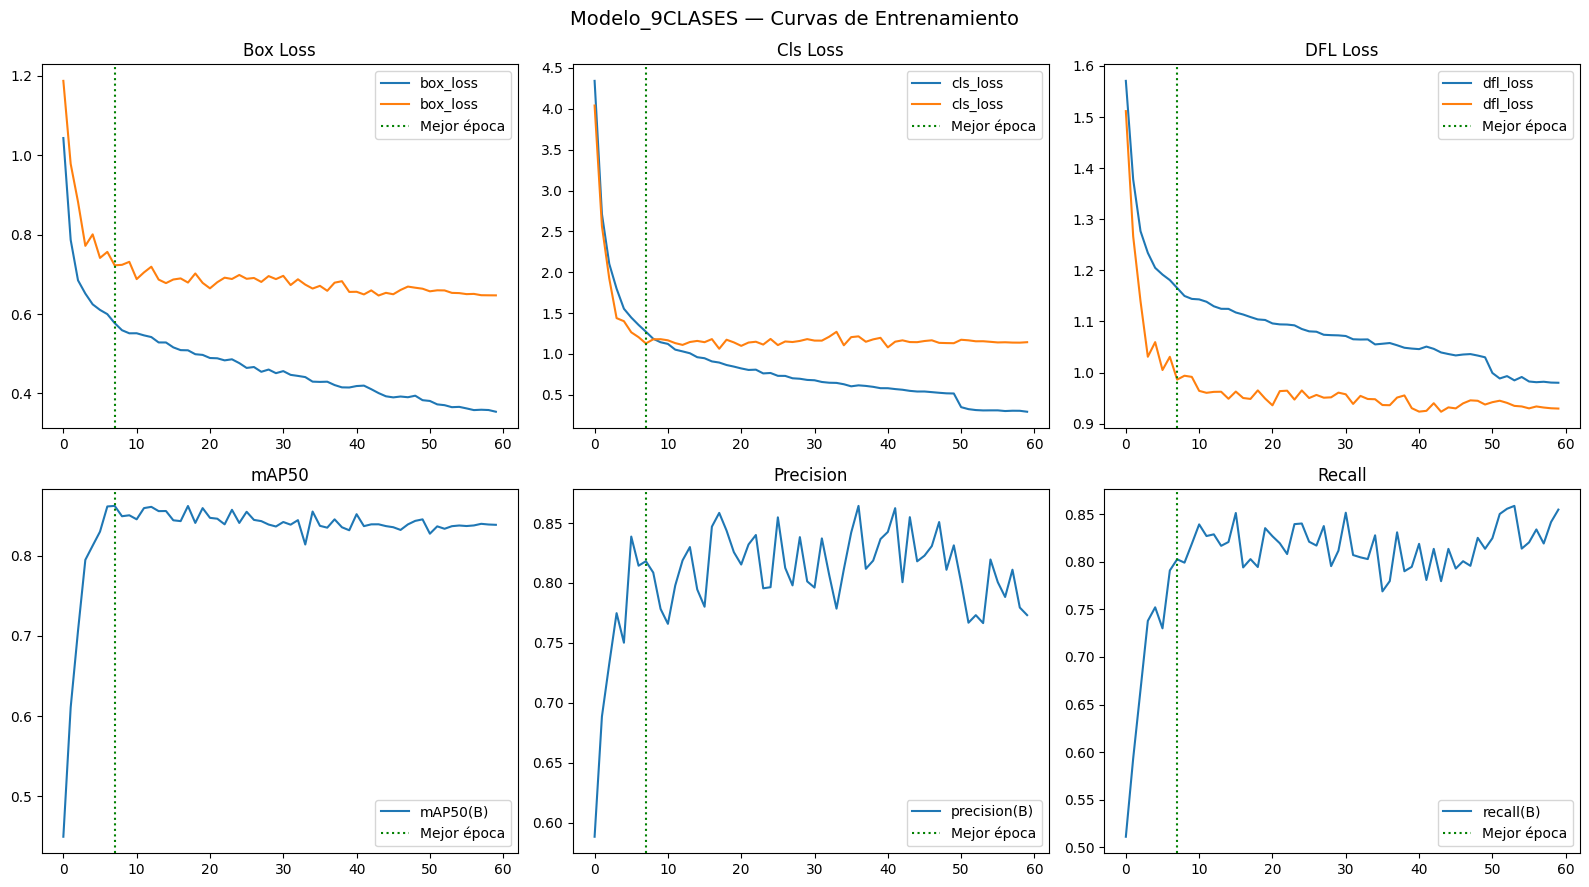

✅ Curvas de entrenamiento guardadas.

📂 Todos los archivos en: /content/drive/MyDrive/10mo Ciclo/TALLER/PRUEBA 1/Modelo_9CLASES/reporte_final


In [21]:
# ============================================================
# REPORTE FINAL — Métricas del pipeline COMPLETO (nivel imagen)
# ============================================================
import os, cv2, numpy as np, pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from ultralytics import YOLO
from collections import defaultdict

# --- Rutas y configuración (heredadas del notebook) ---
dataset_path   = f'{DATASET_LOCAL}/test/images'
labels_path    = f'{DATASET_LOCAL}/test/labels'
results_path   = RESULTS_DIR                          # antes: 'results_path' suelto
carpeta_salida = f'{RESULTS_DIR}/reporte_final'
os.makedirs(carpeta_salida, exist_ok=True)

clases      = CLASSES
extensiones = {'.jpg', '.jpeg', '.png'}
clase_idx   = {c: i for i, c in enumerate(clases)}
n           = len(clases)

# --- Modelos del pipeline (reutiliza los ya cargados) ---
try:
    model1 = model_leaf_pipe
    model2 = model_dis_pipe
    print('Usando modelos ya cargados en el pipeline.')
except NameError:
    model1 = YOLO(f'{LEAF_RESULTS_DIR}/weights/best.pt')
    model2 = YOLO(f'{RESULTS_DIR}/weights/best.pt')
    print('Modelos cargados desde disco.')

CONF_HOJA_PIPE = 0.20    # valor del script original
CONF_ENF_PIPE  = CONF    # 0.15 heredado del notebook
print(f'Conf hoja={CONF_HOJA_PIPE}  |  conf enfermedad={CONF_ENF_PIPE}')

# ── 1. Recolectar predicciones y ground truth ────────────────
all_predictions   = []
all_ground_truths = []
matriz = np.zeros((n + 1, n + 1), dtype=int)

verdaderos_positivos = defaultdict(int)
falsos_negativos     = defaultdict(int)
falsos_positivos     = defaultdict(int)
rechazadas = 0
total_imgs = 0

for img_id, img_file in enumerate(sorted(os.listdir(dataset_path))):
    if os.path.splitext(img_file)[1].lower() not in extensiones:
        continue
    label_file = os.path.splitext(img_file)[0] + '.txt'
    label_path = os.path.join(labels_path, label_file)
    if not os.path.exists(label_path):
        continue
    with open(label_path, 'r') as f:
        lineas = f.readlines()
    if not lineas:
        continue

    imagen = cv2.imread(os.path.join(dataset_path, img_file))
    h, w = imagen.shape[:2]
    total_imgs += 1

    # Ground truth
    clases_reales = []
    for linea in lineas:
        vals = linea.strip().split()
        if not vals:
            continue
        cls = int(vals[0])
        cx, cy, bw, bh = map(float, vals[1:5])
        x1 = (cx - bw/2)*w; y1 = (cy - bh/2)*h
        x2 = (cx + bw/2)*w; y2 = (cy + bh/2)*h
        all_ground_truths.append([img_id, cls, x1, y1, x2, y2])
        clases_reales.append(clases[cls])

    # --- Etapa 1: detector de hoja ---
    r1 = model1(imagen, conf=CONF_HOJA_PIPE, verbose=False)
    if len(r1[0].boxes) == 0:
        rechazadas += 1
        for c in clases_reales:
            falsos_negativos[c] += 1
            matriz[n][clase_idx[c]] += 1     # pred=background, true=c
        continue

    # --- Etapa 2: modelo de enfermedades ---
    r2 = model2(imagen, conf=CONF_ENF_PIPE, verbose=False)
    clases_predichas = [model2.names[int(b.cls)] for b in r2[0].boxes]

    for box in r2[0].boxes:
        cls  = int(box.cls)
        conf = float(box.conf)
        x1, y1, x2, y2 = box.xyxy[0].cpu().numpy()
        all_predictions.append([img_id, cls, conf, x1, y1, x2, y2])

    for c in clases_reales:
        if c in clases_predichas:
            verdaderos_positivos[c] += 1
            matriz[clase_idx[c]][clase_idx[c]] += 1
        else:
            falsos_negativos[c] += 1
            matriz[n][clase_idx[c]] += 1     # pred=background, true=c

    for c in clases_predichas:
        if c not in clases_reales:
            falsos_positivos[c] += 1
            matriz[clase_idx[c]][n] += 1     # pred=c, true=background

# ── 2. Precision / Recall / F1 por clase ─────────────────────
print('\n=== MÉTRICAS DEL PIPELINE COMPLETO ===\n')
print(f'Total imágenes test: {total_imgs}')
print(f'Rechazadas por Modelo Hoja: {rechazadas} ({rechazadas/total_imgs:.1%})\n')

precisions, recalls, f1s = [], [], []
for c in clases:
    tp = verdaderos_positivos[c]
    fn = falsos_negativos[c]
    fp = falsos_positivos[c]
    p  = tp/(tp+fp) if (tp+fp) > 0 else 0
    r  = tp/(tp+fn) if (tp+fn) > 0 else 0
    f1 = 2*p*r/(p+r) if (p+r) > 0 else 0
    precisions.append(p); recalls.append(r); f1s.append(f1)
    print(f'{c:28s} P={p:.2%}  R={r:.2%}  F1={f1:.2%}')

print(f'\nPrecision media: {np.mean(precisions):.2%}')
print(f'Recall medio:    {np.mean(recalls):.2%}')
print(f'F1 medio:        {np.mean(f1s):.2%}')

# ── 3. mAP50 y mAP50-95 (cálculo manual por IoU) ─────────────
def calcular_ap(preds, gts, cls_id, iou_thresh):
    cls_preds = sorted([p for p in preds if p[1] == cls_id], key=lambda x: -x[2])
    cls_gts   = [g for g in gts  if g[1] == cls_id]
    if not cls_gts:
        return 0.0
    matched = set()
    tp_list, fp_list = [], []
    for pred in cls_preds:
        px1, py1, px2, py2 = pred[3:7]
        best_iou, best_idx = 0, -1
        for i, gt in enumerate(cls_gts):
            if gt[0] != pred[0] or i in matched:
                continue
            gx1, gy1, gx2, gy2 = gt[2:6]
            ix1 = max(px1, gx1); iy1 = max(py1, gy1)
            ix2 = min(px2, gx2); iy2 = min(py2, gy2)
            inter = max(0, ix2-ix1) * max(0, iy2-iy1)
            union = (px2-px1)*(py2-py1) + (gx2-gx1)*(gy2-gy1) - inter
            iou   = inter/union if union > 0 else 0
            if iou > best_iou:
                best_iou, best_idx = iou, i
        if best_iou >= iou_thresh and best_idx >= 0:
            tp_list.append(1); fp_list.append(0); matched.add(best_idx)
        else:
            tp_list.append(0); fp_list.append(1)
    tp_cum = np.cumsum(tp_list); fp_cum = np.cumsum(fp_list)
    rec    = tp_cum/len(cls_gts)
    prec   = tp_cum/(tp_cum + fp_cum)
    return sum(np.max(prec[rec >= t]) if any(rec >= t) else 0
               for t in np.arange(0, 1.1, 0.1)) / 11

print('\n=== mAP50 y mAP50-95 DEL PIPELINE ===\n')
aps50, aps5095 = [], []
for i, c in enumerate(clases):
    ap50   = calcular_ap(all_predictions, all_ground_truths, i, 0.5)
    ap5095 = np.mean([calcular_ap(all_predictions, all_ground_truths, i, t)
                      for t in np.arange(0.5, 1.0, 0.05)])
    aps50.append(ap50); aps5095.append(ap5095)
    print(f'{c:28s} mAP50={ap50:.4f}  mAP50-95={ap5095:.4f}')

print(f'\nmAP50 global:    {np.mean(aps50):.4f}')
print(f'mAP50-95 global: {np.mean(aps5095):.4f}')

# ── 4. Matriz de confusión (Pipeline) ────────────────────────
labels_plot = clases + ['background']
fig, axes = plt.subplots(1, 2, figsize=(26, 10))
sns.heatmap(matriz, annot=True, fmt='d', cmap='Blues',
            xticklabels=labels_plot, yticklabels=labels_plot, ax=axes[0])
axes[0].set_title('Confusion Matrix — Pipeline Completo', fontsize=13)
axes[0].set_ylabel('Predicted'); axes[0].set_xlabel('True')

col_sums = matriz.sum(axis=0); col_sums[col_sums == 0] = 1
matriz_norm = matriz.astype(float) / col_sums
sns.heatmap(matriz_norm, annot=True, fmt='.2f', cmap='Blues',
            xticklabels=labels_plot, yticklabels=labels_plot, ax=axes[1])
axes[1].set_title('Confusion Matrix Normalized — Pipeline Completo', fontsize=13)
axes[1].set_ylabel('Predicted'); axes[1].set_xlabel('True')

plt.tight_layout()
plt.savefig(f'{carpeta_salida}/confusion_matrix_pipeline.png', dpi=150, bbox_inches='tight')
plt.show()
print('✅ Matriz de confusión guardada.')

# ── 5. Curvas de entrenamiento ───────────────────────────────
df = pd.read_csv(f'{results_path}/results.csv')
df.columns = df.columns.str.strip()
mejor_epoca = df['metrics/mAP50(B)'].idxmax()

fig, axes = plt.subplots(2, 3, figsize=(16, 9))
fig.suptitle(f'{RUN_NAME_DISEASE} — Curvas de Entrenamiento', fontsize=14)

for ax, (title, cols) in zip(axes.flat, [
        ('Box Loss',  ['train/box_loss', 'val/box_loss']),
        ('Cls Loss',  ['train/cls_loss', 'val/cls_loss']),
        ('DFL Loss',  ['train/dfl_loss', 'val/dfl_loss']),
        ('mAP50',     ['metrics/mAP50(B)']),
        ('Precision', ['metrics/precision(B)']),
        ('Recall',    ['metrics/recall(B)'])]):
    for c in cols:
        ax.plot(df[c], label=c.split('/')[-1])
    ax.axvline(mejor_epoca, color='g', linestyle=':', label='Mejor época')
    ax.set_title(title); ax.legend()

plt.tight_layout()
plt.savefig(f'{carpeta_salida}/curvas_entrenamiento_{RUN_NAME_DISEASE}.png',
            dpi=150, bbox_inches='tight')
plt.show()
print('✅ Curvas de entrenamiento guardadas.')

print(f'\n📂 Todos los archivos en: {carpeta_salida}')

Usando modelos ya cargados del pipeline.
Conf hoja=0.2  |  conf enfermedad=0.15

  MÉTRICAS DEL PIPELINE COMPLETO — 274 imágenes de test
                  Clase  Support  TP  FP  FN Precision  Recall     F1 Accuracy
 AmarillamientoAvanzado       27  23  11   4    67.65%  85.19% 75.41%   94.53%
  AmarillamientoInicial       20  13   4   7    76.47%  65.00% 70.27%   95.99%
      CogolleroAvanzado       50  50   7   0    87.72% 100.00% 93.46%   97.45%
       CogolleroInicial       64  62   4   2    93.94%  96.88% 95.38%   97.81%
PodredumbreRojaAvanzado       33  27  12   6    69.23%  81.82% 75.00%   93.43%
 PodredumbreRojaInicial       19  10   2   9    83.33%  52.63% 64.52%   95.99%
           RoyaAvanzado       23  20   4   3    83.33%  86.96% 85.11%   97.45%
            RoyaInicial       15  12   4   3    75.00%  80.00% 77.42%   97.45%
              Saludable       30  30   1   0    96.77% 100.00% 98.36%   99.64%

  MÉTRICAS GLOBALES DEL PIPELINE

  Imágenes totales            : 274
  

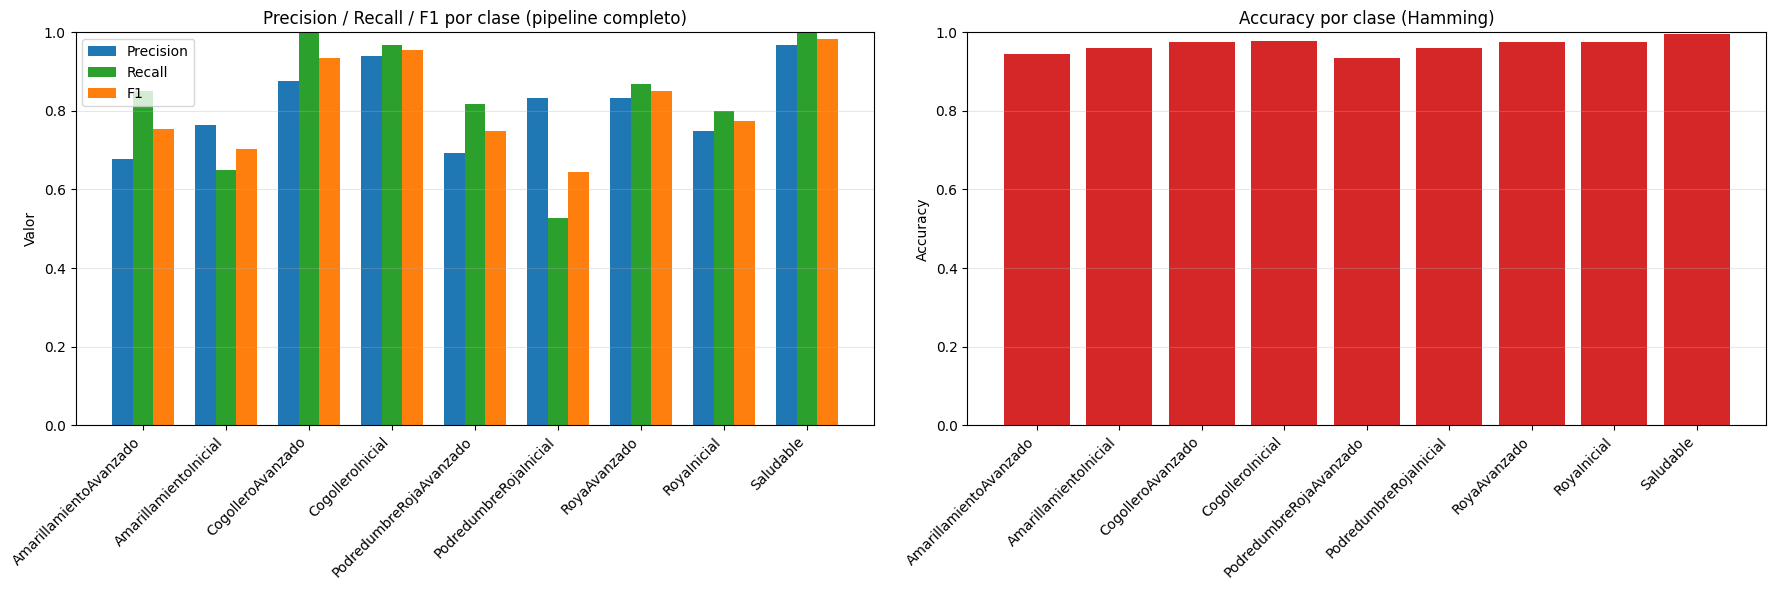

💾 Gráfica: /content/drive/MyDrive/10mo Ciclo/TALLER/PRUEBA 1/Modelo_9CLASES/reporte_final/metricas_pipeline_por_clase.png


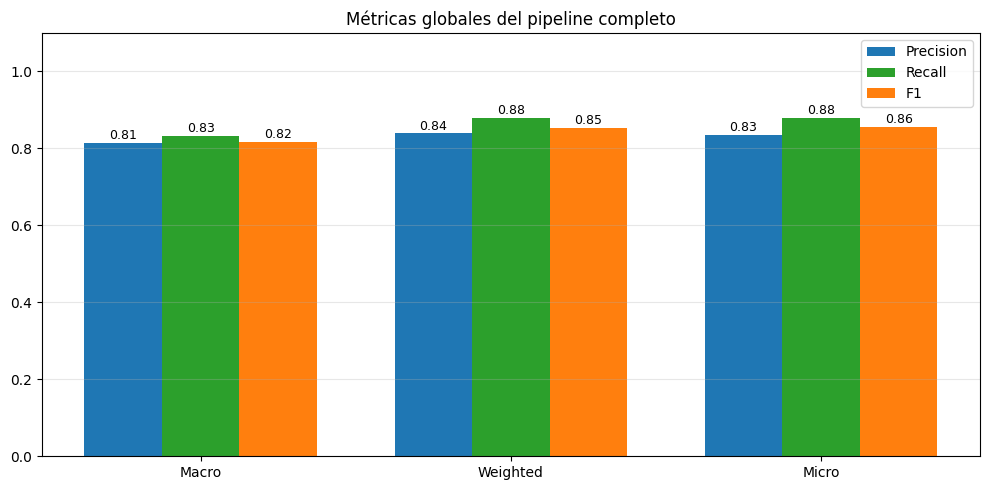

💾 Gráfica: /content/drive/MyDrive/10mo Ciclo/TALLER/PRUEBA 1/Modelo_9CLASES/reporte_final/metricas_pipeline_global.png


In [22]:
# ============================================================
# MÉTRICAS DEL PIPELINE COMPLETO — Precision / Accuracy / Recall / F1
# ============================================================
import os, cv2, numpy as np, pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from ultralytics import YOLO

# --- Config ---
dataset_path   = f'{DATASET_LOCAL}/test/images'
labels_path    = f'{DATASET_LOCAL}/test/labels'
extensiones    = {'.jpg', '.jpeg', '.png'}
carpeta_salida = f'{RESULTS_DIR}/reporte_final'
os.makedirs(carpeta_salida, exist_ok=True)

clases    = CLASSES
clase_idx = {c: i for i, c in enumerate(clases)}
n         = len(clases)

# --- Modelos ---
try:
    m_leaf = model_leaf_pipe
    m_dis  = model_dis_pipe
    print('Usando modelos ya cargados del pipeline.')
except NameError:
    m_leaf = YOLO(f'{LEAF_RESULTS_DIR}/weights/best.pt')
    m_dis  = YOLO(f'{RESULTS_DIR}/weights/best.pt')
    print('Modelos cargados desde disco.')

CONF_HOJA_PIPE = 0.20
CONF_ENF_PIPE  = CONF
print(f'Conf hoja={CONF_HOJA_PIPE}  |  conf enfermedad={CONF_ENF_PIPE}')

# --- Contadores por clase (multi-label por imagen) ---
TP = np.zeros(n, dtype=int)
FP = np.zeros(n, dtype=int)
FN = np.zeros(n, dtype=int)
support = np.zeros(n, dtype=int)

total_imgs = 0
rechazadas = 0
exact_match_ok = 0

for img_file in sorted(os.listdir(dataset_path)):
    ext = os.path.splitext(img_file)[1].lower()
    if ext not in extensiones:
        continue
    label_file = os.path.splitext(img_file)[0] + '.txt'
    label_path = os.path.join(labels_path, label_file)
    if not os.path.exists(label_path):
        continue
    with open(label_path) as f:
        lineas = [l for l in f.readlines() if l.strip()]
    if not lineas:
        continue

    imagen = cv2.imread(os.path.join(dataset_path, img_file))
    if imagen is None:
        continue
    total_imgs += 1

    # Ground truth (set de clases presentes)
    gt_classes = sorted({int(l.split()[0]) for l in lineas})
    for c in gt_classes:
        support[c] += 1

    # --- Etapa 1: detector de hoja ---
    r1 = m_leaf(imagen, conf=CONF_HOJA_PIPE, verbose=False)
    if len(r1[0].boxes) == 0:
        rechazadas += 1
        for c in gt_classes:
            FN[c] += 1
        continue

    # --- Etapa 2: modelo de enfermedades ---
    r2 = m_dis(imagen, conf=CONF_ENF_PIPE, verbose=False)
    pred_classes = sorted({int(b.cls) for b in r2[0].boxes})

    for c in gt_classes:
        if c in pred_classes:
            TP[c] += 1
        else:
            FN[c] += 1
    for c in pred_classes:
        if c not in gt_classes:
            FP[c] += 1

    if set(gt_classes) == set(pred_classes):
        exact_match_ok += 1

# --- Derivados por clase ---
TN = total_imgs - TP - FP - FN

precision_c = np.divide(TP, TP + FP, out=np.zeros(n), where=(TP + FP) > 0)
recall_c    = np.divide(TP, TP + FN, out=np.zeros(n), where=(TP + FN) > 0)
f1_c        = np.divide(2 * precision_c * recall_c,
                        precision_c + recall_c,
                        out=np.zeros(n),
                        where=(precision_c + recall_c) > 0)
accuracy_c  = (TP + TN) / max(total_imgs, 1)   # Hamming accuracy por clase

# --- Tabla por clase ---
df_metrics = pd.DataFrame({
    'Clase'    : clases,
    'Support'  : support,
    'TP'       : TP,
    'FP'       : FP,
    'FN'       : FN,
    'Precision': precision_c,
    'Recall'   : recall_c,
    'F1'       : f1_c,
    'Accuracy' : accuracy_c,
})
df_print = df_metrics.copy()
for col in ['Precision', 'Recall', 'F1', 'Accuracy']:
    df_print[col] = df_print[col].map(lambda x: f'{x:.2%}')

print('\n' + '=' * 92)
print(f'  MÉTRICAS DEL PIPELINE COMPLETO — {total_imgs} imágenes de test')
print('=' * 92)
print(df_print.to_string(index=False))

# --- Métricas globales ---
macro_p  = precision_c.mean()
macro_r  = recall_c.mean()
macro_f1 = f1_c.mean()

total_support = support.sum()
weighted_p  = (precision_c * support).sum() / total_support if total_support else 0
weighted_r  = (recall_c    * support).sum() / total_support if total_support else 0
weighted_f1 = (f1_c        * support).sum() / total_support if total_support else 0

micro_tp = TP.sum(); micro_fp = FP.sum(); micro_fn = FN.sum()
micro_p  = micro_tp / (micro_tp + micro_fp) if (micro_tp + micro_fp) else 0
micro_r  = micro_tp / (micro_tp + micro_fn) if (micro_tp + micro_fn) else 0
micro_f1 = 2 * micro_p * micro_r / (micro_p + micro_r) if (micro_p + micro_r) else 0

accuracy_global_hamming = (TP.sum() + TN.sum()) / max(total_imgs * n, 1)
accuracy_global_exact   = exact_match_ok / max(total_imgs, 1)
aceptadas      = total_imgs - rechazadas
tasa_aceptadas = aceptadas / total_imgs if total_imgs else 0

print('\n' + '=' * 60)
print('  MÉTRICAS GLOBALES DEL PIPELINE')
print('=' * 60)
print(f'\n  Imágenes totales            : {total_imgs}')
print(f'  Hojas aceptadas por etapa 1 : {aceptadas} ({tasa_aceptadas:.2%})')
print(f'  Rechazadas por etapa 1      : {rechazadas} ({rechazadas/total_imgs:.2%})')

print('\n  --- Precision / Recall / F1 ---')
print(f'  Macro    Precision : {macro_p:.2%}')
print(f'  Macro    Recall    : {macro_r:.2%}')
print(f'  Macro    F1        : {macro_f1:.2%}')
print(f'  Weighted Precision : {weighted_p:.2%}')
print(f'  Weighted Recall    : {weighted_r:.2%}')
print(f'  Weighted F1        : {weighted_f1:.2%}')
print(f'  Micro    Precision : {micro_p:.2%}')
print(f'  Micro    Recall    : {micro_r:.2%}')
print(f'  Micro    F1        : {micro_f1:.2%}')

print('\n  --- Accuracy ---')
print(f'  Hamming (por clase) : {accuracy_global_hamming:.2%}')
print(f'  Exact Match         : {accuracy_global_exact:.2%}')

# --- Guardar CSV ---
df_metrics.to_csv(f'{carpeta_salida}/metricas_pipeline_por_clase.csv', index=False)
print(f'\n💾 CSV: {carpeta_salida}/metricas_pipeline_por_clase.csv')

# --- Gráfica 1: barras por clase ---
fig, axes = plt.subplots(1, 2, figsize=(18, 6))
x = np.arange(n); w = 0.25
axes[0].bar(x - w, precision_c, w, label='Precision', color='#1f77b4')
axes[0].bar(x,      recall_c,    w, label='Recall',    color='#2ca02c')
axes[0].bar(x + w,  f1_c,        w, label='F1',        color='#ff7f0e')
axes[0].set_xticks(x); axes[0].set_xticklabels(clases, rotation=45, ha='right')
axes[0].set_ylim(0, 1); axes[0].set_ylabel('Valor')
axes[0].set_title('Precision / Recall / F1 por clase (pipeline completo)')
axes[0].legend(); axes[0].grid(axis='y', alpha=0.3)

axes[1].bar(x, accuracy_c, color='#d62728')
axes[1].set_xticks(x); axes[1].set_xticklabels(clases, rotation=45, ha='right')
axes[1].set_ylim(0, 1); axes[1].set_ylabel('Accuracy')
axes[1].set_title('Accuracy por clase (Hamming)')
axes[1].grid(axis='y', alpha=0.3)

plt.tight_layout()
p1 = f'{carpeta_salida}/metricas_pipeline_por_clase.png'
plt.savefig(p1, dpi=150, bbox_inches='tight')
plt.show()
print(f'💾 Gráfica: {p1}')

# --- Gráfica 2: métricas globales ---
fig, ax = plt.subplots(figsize=(10, 5))
groups = ['Macro', 'Weighted', 'Micro']
p_vals = [macro_p,  weighted_p,  micro_p]
r_vals = [macro_r,  weighted_r,  micro_r]
f_vals = [macro_f1, weighted_f1, micro_f1]
x = np.arange(len(groups)); w = 0.25
ax.bar(x - w, p_vals, w, label='Precision', color='#1f77b4')
ax.bar(x,      r_vals, w, label='Recall',    color='#2ca02c')
ax.bar(x + w,  f_vals, w, label='F1',        color='#ff7f0e')
for xi, v in zip(x, p_vals): ax.text(xi - w, v + 0.01, f'{v:.2f}', ha='center', fontsize=9)
for xi, v in zip(x, r_vals): ax.text(xi,     v + 0.01, f'{v:.2f}', ha='center', fontsize=9)
for xi, v in zip(x, f_vals): ax.text(xi + w, v + 0.01, f'{v:.2f}', ha='center', fontsize=9)
ax.set_xticks(x); ax.set_xticklabels(groups)
ax.set_ylim(0, 1.1); ax.set_title('Métricas globales del pipeline completo')
ax.legend(); ax.grid(axis='y', alpha=0.3)
plt.tight_layout()
p2 = f'{carpeta_salida}/metricas_pipeline_global.png'
plt.savefig(p2, dpi=150, bbox_inches='tight')
plt.show()
print(f'💾 Gráfica: {p2}')

In [23]:
# ============================================================
# MUESTREO ALEATORIO — Pipeline sobre imágenes del dataset
# ============================================================
import os, cv2, random, glob
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from ultralytics import YOLO

# ---------------- CONFIG ----------------
N_IMAGENES      = 12          # cuántas imágenes aleatorias mostrar
SPLIT           = 'test'      # 'test', 'valid' o 'train'
SEED            = 42          # para reproducibilidad (None = aleatorio real)
MOSTRAR_GT      = True        # anota también el ground truth
CONF_HOJA_PIPE  = 0.20
CONF_ENF_PIPE   = CONF

# ---------------- Modelos ----------------
try:
    m_leaf = model_leaf_pipe
    m_dis  = model_dis_pipe
    print('Usando modelos ya cargados.')
except NameError:
    m_leaf = YOLO(f'{LEAF_RESULTS_DIR}/weights/best.pt')
    m_dis  = YOLO(f'{RESULTS_DIR}/weights/best.pt')
    print('Modelos cargados desde disco.')

# ---------------- Recursos ----------------
IMGS_DIR = f'{DATASET_LOCAL}/{SPLIT}/images'
LBL_DIR  = f'{DATASET_LOCAL}/{SPLIT}/labels'
OUT_DIR  = f'{RESULTS_DIR}/muestreo_{SPLIT}'
os.makedirs(OUT_DIR, exist_ok=True)

EXT = ('.jpg', '.jpeg', '.png', '.bmp', '.webp')

def leer_gt(img_path):
    """Devuelve la lista de nombres de clase presentes en el label YOLO."""
    base = os.path.splitext(os.path.basename(img_path))[0]
    lbl = os.path.join(LBL_DIR, base + '.txt')
    if not os.path.exists(lbl):
        return []
    with open(lbl) as f:
        ids = sorted({int(l.split()[0]) for l in f if l.strip()})
    return [CLASSES[i] for i in ids]

def correr_pipeline(img_path):
    """Devuelve (es_hoja, conf_hoja, enfermedad_top, conf_enfermedad, todas)."""
    r1 = m_leaf(img_path, conf=CONF_HOJA_PIPE, verbose=False)[0]
    if len(r1.boxes) == 0:
        return False, 0.0, None, 0.0, [], r1, None

    conf_hoja = float(r1.boxes.conf.max())
    r2 = m_dis(img_path, conf=CONF_ENF_PIPE, verbose=False)[0]
    if len(r2.boxes) == 0:
        return True, conf_hoja, None, 0.0, [], r1, r2

    idx = int(r2.boxes.conf.argmax())
    cls_top  = m_dis.names[int(r2.boxes.cls[idx])]
    conf_top = float(r2.boxes.conf[idx])
    todas    = [(m_dis.names[int(b.cls)], float(b.conf)) for b in r2.boxes]
    return True, conf_hoja, cls_top, conf_top, todas, r1, r2

# ---------------- Selección aleatoria ----------------
todas_imgs = [p for p in glob.glob(f'{IMGS_DIR}/*') if p.lower().endswith(EXT)]
if not todas_imgs:
    raise FileNotFoundError(f'No hay imágenes en {IMGS_DIR}')

if SEED is not None:
    random.seed(SEED)
muestra = random.sample(todas_imgs, min(N_IMAGENES, len(todas_imgs)))

print(f'\nDataset: {IMGS_DIR}')
print(f'Total disponibles : {len(todas_imgs)}')
print(f'Muestra aleatoria : {len(muestra)} imágenes (seed={SEED})\n')

# ---------------- Inferencia ----------------
filas = []
resultados = []
for p in muestra:
    gt = leer_gt(p)
    es_hoja, c_hoja, enf, c_enf, todas, r1, r2 = correr_pipeline(p)

    filas.append({
        'imagen'         : os.path.basename(p),
        'ground_truth'   : ', '.join(gt) if gt else '(sin label)',
        'paso_etapa_1'   : 'Sí' if es_hoja else 'No',
        'conf_hoja'      : f'{c_hoja:.2%}' if es_hoja else '—',
        'prediccion'     : enf if enf else ('(nada)' if es_hoja else 'RECHAZADA'),
        'conf_enfermedad': f'{c_enf:.2%}' if enf else '—',
        'acierto_global' : '✅' if (set(gt) == set([t[0] for t in todas])) else '❌',
        'todas_detectadas': ' | '.join(f'{c}:{v:.0%}' for c, v in todas) or '—',
    })
    resultados.append((p, gt, es_hoja, c_hoja, enf, c_enf, todas, r1, r2))

df = pd.DataFrame(filas)
print('=' * 110)
print(f'  RESULTADOS DEL PIPELINE — {len(muestra)} imágenes aleatorias ({SPLIT})')
print('=' * 110)
print(df.to_string(index=False))

# ---------------- Grid visual ----------------
def anotar(ax, img_rgb, titulo, gt=None, pred=None, color='black'):
    ax.imshow(img_rgb)
    ax.set_title(titulo, fontsize=9, color=color)
    ax.axis('off')
    if MOSTRAR_GT:
        txt = []
        if gt is not None:  txt.append(f'GT: {", ".join(gt) or "∅"}')
        if pred is not None: txt.append(f'Pred: {pred}')
        ax.text(0.02, 0.02, '\n'.join(txt), transform=ax.transAxes,
                fontsize=7, color='white',
                bbox=dict(facecolor='black', alpha=0.55, edgecolor='none', pad=2))

ncols = 3
nrows = (len(resultados) + ncols - 1) // ncols
fig, axes = plt.subplots(nrows, ncols, figsize=(5 * ncols, 4.2 * nrows))
axes = np.array(axes).flatten()
fig.suptitle(f'Pipeline CañaScan — muestreo aleatorio ({SPLIT}, {len(resultados)} imgs)',
             fontsize=14)

for i, (p, gt, es_hoja, c_hoja, enf, c_enf, todas, r1, r2) in enumerate(resultados):
    ax = axes[i]
    img_bgr = cv2.imread(p)
    img_rgb = cv2.cvtColor(img_bgr, cv2.COLOR_BGR2RGB)

    # Elegimos qué mostrar según el resultado
    if not es_hoja:
        anotar(ax, img_rgb,
               f'{i+1}) RECHAZADA — no hoja',
               gt=gt, pred='RECHAZADA', color='crimson')
    else:
        # Overlay de ambas etapas (hoja con línea verde, enfermedad con su caja)
        vis = cv2.cvtColor(r2.plot(), cv2.COLOR_BGR2RGB) if r2 is not None else img_rgb
        if r1 is not None:
            for b in r1.boxes:
                x1, y1, x2, y2 = map(int, b.xyxy[0].tolist())
                cv2.rectangle(vis, (x1, y1), (x2, y2), (0, 255, 0), 2)
        pred_txt = enf if enf else 'sin detección'
        color = 'darkgreen' if set(gt) == set([t[0] for t in todas]) else 'darkorange'
        anotar(ax, vis,
               f'{i+1}) {pred_txt} ({c_enf:.0%})',
               gt=gt, pred=pred_txt, color=color)

for j in range(len(resultados), len(axes)):
    axes[j].axis('off')

plt.tight_layout()
out_png = f'{OUT_DIR}/muestra_{SPLIT}_{len(muestra)}imgs.png'
plt.savefig(out_png, dpi=150, bbox_inches='tight')
plt.show()
print(f'\n💾 Grid guardado: {out_png}')

# ---------------- Resumen estadístico ----------------
aciertos    = (df['acierto_global'] == '✅').sum()
aceptadas   = (df['paso_etapa_1'] == 'Sí').sum()
rechazadas  = len(df) - aceptadas

print('\n' + '=' * 60)
print('  RESUMEN DEL MUESTREO')
print('=' * 60)
print(f'  Total mostradas       : {len(df)}')
print(f'  Aceptadas (etapa 1)   : {aceptadas}')
print(f'  Rechazadas (etapa 1)  : {rechazadas}')
print(f'  Aciertos exactos GT   : {aciertos}/{len(df)} ({aciertos/len(df):.1%})')

# ---------------- CSV ----------------
csv_path = f'{OUT_DIR}/muestra_{SPLIT}_{len(muestra)}imgs.csv'
df.to_csv(csv_path, index=False)
print(f'\n💾 CSV: {csv_path}')

Output hidden; open in https://colab.research.google.com to view.

# ✅ Resumen final

## Artefactos generados

**Enfermedades (9 clases)** — `{BASE_DRIVE}/{RUN_NAME_DISEASE}/`
- `weights/best.pt`, `weights/epoch{mejor_epoca}.pt`
- `results.csv`, `metricas_*.png`
- `heatmaps/` — GradCAM por clase
- `matriz_confusion_{RUN_NAME_DISEASE}.png`

**Detector de hoja** — `{BASE_DRIVE}/{RUN_NAME_LEAF}/`
- `weights/best.pt`
- `matriz_confusion_{RUN_NAME_LEAF}.png`

**Pipeline (prueba_real)** — `{PRUEBA_REAL_DIR}/resultados/`
- `hojas/` y `negativos/` (visualizaciones)
- `resumen_hojas.csv`, `resumen_negativos.csv`
- `graficas_pipeline.png`
- `matriz_confusion_pipeline.png`
